In [1]:
Import Required Libraries

import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Regression Models
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import PolynomialFeatures

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Model Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Step 2: Load DMart Dataset

from tkinter import Tk, filedialog

root = Tk()
root.withdraw()

file_path = filedialog.askopenfilename(
    title="Select DMart Excel Dataset",
    filetypes=[("Excel Files", "*.xlsx")]
)

root.destroy()

df = pd.read_excel(file_path)

print("Dataset imported successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset imported successfully!
Dataset Shape: (25000, 31)


,Customer_ID,Product_ID,Order_ID,Customer_Age,Gender,Product_Name,MRP,Discount_Price,Category,State,...,Pin_Code,Total_Order_Value,Payment_Status,No_of_Clicks,Year,Month,Shipping_Charges,Discount_Amount,Discount_Percentage,Age_Group
0,YSB75,BW653,479577309,28,Female,Ariel Matic Top Load Liquid Detergent,977.44,909.02,Imported,Andhra Pradesh,...,318324,909.02,Paid,29,2022,May,0,68.42,0.07,25-34
1,FUS93,XV061,634865221,47,Male,VSR Channa Dal,834.09,450.41,Branded,Telangana,...,730162,450.41,Paid,95,2021,August,0,383.68,0.46,45-54
2,AJP28,GF695,113166210,63,Female,Tenali Double Horse Chana Dal,1095.20,1007.58,Branded,Gujarat,...,694091,1007.58,Paid,51,2021,October,0,87.62,0.08,55+
3,URC55,VM478,740539230,41,Male,Tata Tea,748.16,389.04,Imported,Maharashtra,...,211807,489.04,Pending,12,2021,August,100,359.12,0.48,35-44
4,ZOP23,XD230,156544145,22,Female,VSR Channa Dal,1249.04,911.80,Local,Gujarat,...,78304,1011.80,Paid,26,2023,December,100,337.24,0.27,18-24


In [5]:
# Step 3: Basic Dataset Exploration

print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
df.describe()

Dataset Shape:
(25000, 31)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Customer_ID              25000 non-null  object        
 1   Product_ID               25000 non-null  str           
 2   Order_ID                 25000 non-null  int64         
 3   Customer_Age             25000 non-null  int64         
 4   Gender                   25000 non-null  str           
 5   Product_Name             25000 non-null  str           
 6   MRP                      25000 non-null  float64       
 7   Discount_Price           25000 non-null  float64       
 8   Category                 25000 non-null  str           
 9   State                    25000 non-null  str           
 10  City                     25000 non-null  str           
 11  Subscription             25000 non-null  str           

,Order_ID,Customer_Age,MRP,Discount_Price,Bill_Number,Time_Spent_on_Website,Rating,Delivery_Date,Cancellation_Date,Pin_Code,Total_Order_Value,No_of_Clicks,Year,Discount_Amount,Discount_Percentage
count,2.500000e+04,25000.000000,25000.000000,25000.000000,2.500000e+04,25000.000000,25000.000000,25000,1784,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,4.987130e+08,43.856600,1013.746646,735.621509,5.016695e+11,10.150932,3.008728,2022-07-10 05:38:34.368000,2022-07-07 01:53:00.269058,496731.079480,678.164373,50.423040,2022.002200,278.125138,0.274444
min,1.912800e+04,18.000000,20.040000,10.910000,2.349474e+07,1.000000,1.000000,2021-01-03 00:00:00,2021-01-12 00:00:00,5.000000,0.000000,1.000000,2021.000000,1.030000,0.049900
25%,2.503746e+08,31.000000,523.995000,367.665000,2.540000e+11,2.980000,2.000000,2021-10-11 00:00:00,2021-09-25 18:00:00,247984.500000,250.157500,26.000000,2021.000000,101.257500,0.160000
50%,4.997311e+08,44.000000,1014.415000,713.140000,5.020000e+11,5.000000,3.000000,2022-07-11 00:00:00,2022-07-14 00:00:00,495215.500000,656.040000,50.000000,2022.000000,220.000000,0.270000
75%,7.471021e+08,57.000000,1506.812500,1061.347500,7.520000e+11,13.430000,4.000000,2023-04-09 00:00:00,2023-04-13 06:00:00,745846.250000,1045.692500,76.000000,2023.000000,412.235000,0.390000
max,9.999131e+08,70.000000,1999.920000,1876.220000,1.000000e+12,59.970000,5.000000,2024-01-09 00:00:00,2024-01-20 00:00:00,999997.000000,2026.220000,100.000000,2023.000000,990.450000,0.500200
std,2.881895e+08,15.285775,571.079711,441.362817,2.887202e+11,10.965989,1.159525,NaN,NaN,287726.921162,488.629285,28.867925,0.816714,218.255926,0.130436


In [6]:
# Missing Values Analysis

missing_values = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing_Values": missing_values,
    "Missing_Percentage": missing_percentage
})

missing_report = missing_report.sort_values(
    by="Missing_Values",
    ascending=False
)

print("Missing Values Report:")
display(missing_report)

# Duplicate Records Analysis

print("Total Duplicate Rows:", df.duplicated().sum())

Missing Values Report:


,Missing_Values,Missing_Percentage
Cancellation_Date,23216,92.864
Payment_Method,1,0.004
Customer_ID,0,0.000
Customer_Age,0,0.000
Gender,0,0.000
Product_ID,0,0.000
Order_ID,0,0.000
Discount_Price,0,0.000
Category,0,0.000
State,0,0.000


Total Duplicate Rows: 0


In [7]:
print("Missing Values in Each Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())



Missing Values in Each Column:
Cancellation_Date    23216
Payment_Method           1
dtype: int64

Total Missing Values: 23217


In [8]:
# Cancellation Date Analysis

cancellation_analysis = pd.crosstab(
    df["Order_Status"],
    df["Cancellation_Date"].isnull(),
    margins=True
)

print(cancellation_analysis)

Cancellation_Date  False   True    All
Order_Status                          
Cancelled           1784      0   1784
Delivered              0  13009  13009
Returned               0   1350   1350
Shipped                0   8857   8857
All                 1784  23216  25000


In [9]:
# Handling Missing Values

df_clean = df.copy()

df_clean["Payment_Method"] = df_clean["Payment_Method"].fillna("Unknown")

print("Missing Values After Cleaning:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nTotal Missing Values:", df_clean.isnull().sum().sum())

Missing Values After Cleaning:
Cancellation_Date    23216
dtype: int64

Total Missing Values: 23216


In [10]:
# Correlation Analysis

numerical_data = df_clean.select_dtypes(include=np.number)

correlation_matrix = numerical_data.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,Order_ID,Customer_Age,MRP,Discount_Price,Bill_Number,Time_Spent_on_Website,Rating,Pin_Code,Total_Order_Value,No_of_Clicks,Year,Discount_Amount,Discount_Percentage
Order_ID,1.00,0.00,-0.01,-0.01,-0.01,-0.00,-0.00,0.00,-0.01,0.00,-0.01,-0.00,0.01
Customer_Age,0.00,1.00,-0.00,-0.00,0.01,0.01,0.00,0.01,0.00,-0.00,0.01,-0.00,-0.00
MRP,-0.01,-0.00,1.00,0.94,0.00,-0.00,0.01,0.00,0.74,0.00,0.01,0.72,-0.00
Discount_Price,-0.01,-0.00,0.94,1.00,0.00,-0.01,0.01,-0.00,0.79,0.00,0.01,0.43,-0.30
Bill_Number,-0.01,0.01,0.00,0.00,1.00,0.00,-0.00,-0.00,-0.00,0.01,0.01,0.00,0.00
Time_Spent_on_Website,-0.00,0.01,-0.00,-0.01,0.00,1.00,-0.00,-0.01,-0.01,0.00,0.00,0.00,0.01
Rating,-0.00,0.00,0.01,0.01,-0.00,-0.00,1.00,-0.00,0.01,-0.01,0.01,0.01,0.00
Pin_Code,0.00,0.01,0.00,-0.00,-0.00,-0.01,-0.00,1.00,-0.01,0.01,-0.01,0.01,0.01
Total_Order_Value,-0.01,0.00,0.74,0.79,-0.00,-0.01,0.01,-0.01,1.00,0.00,0.01,0.34,-0.24
No_of_Clicks,0.00,-0.00,0.00,0.00,0.01,0.00,-0.01,0.01,0.00,1.00,-0.01,-0.00,0.00


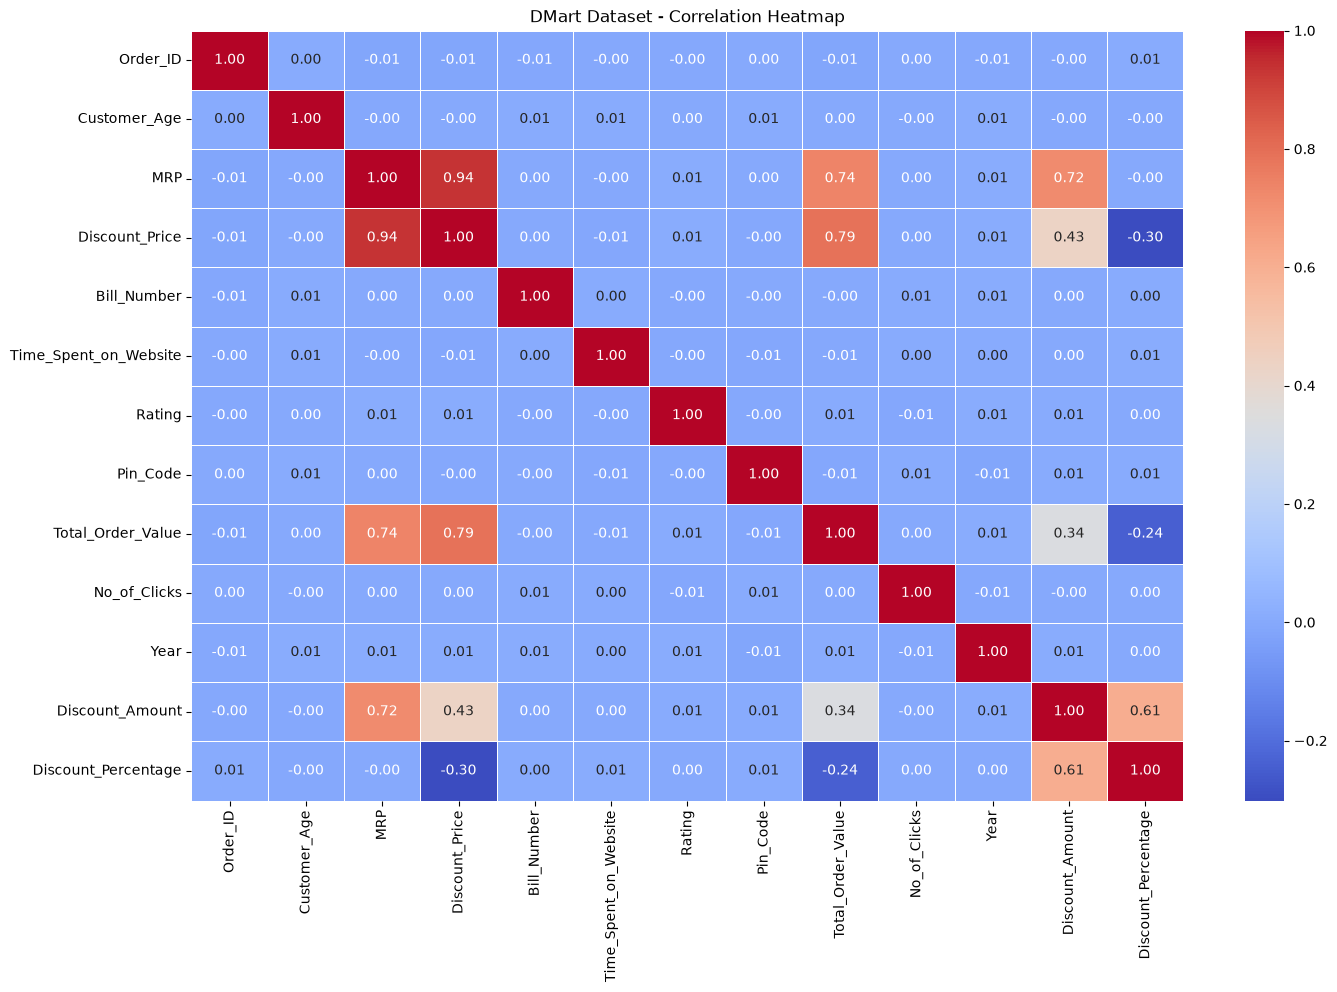

In [11]:
# Correlation Heatmap

plt.figure(figsize=(16, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("DMart Dataset - Correlation Heatmap")
plt.show()

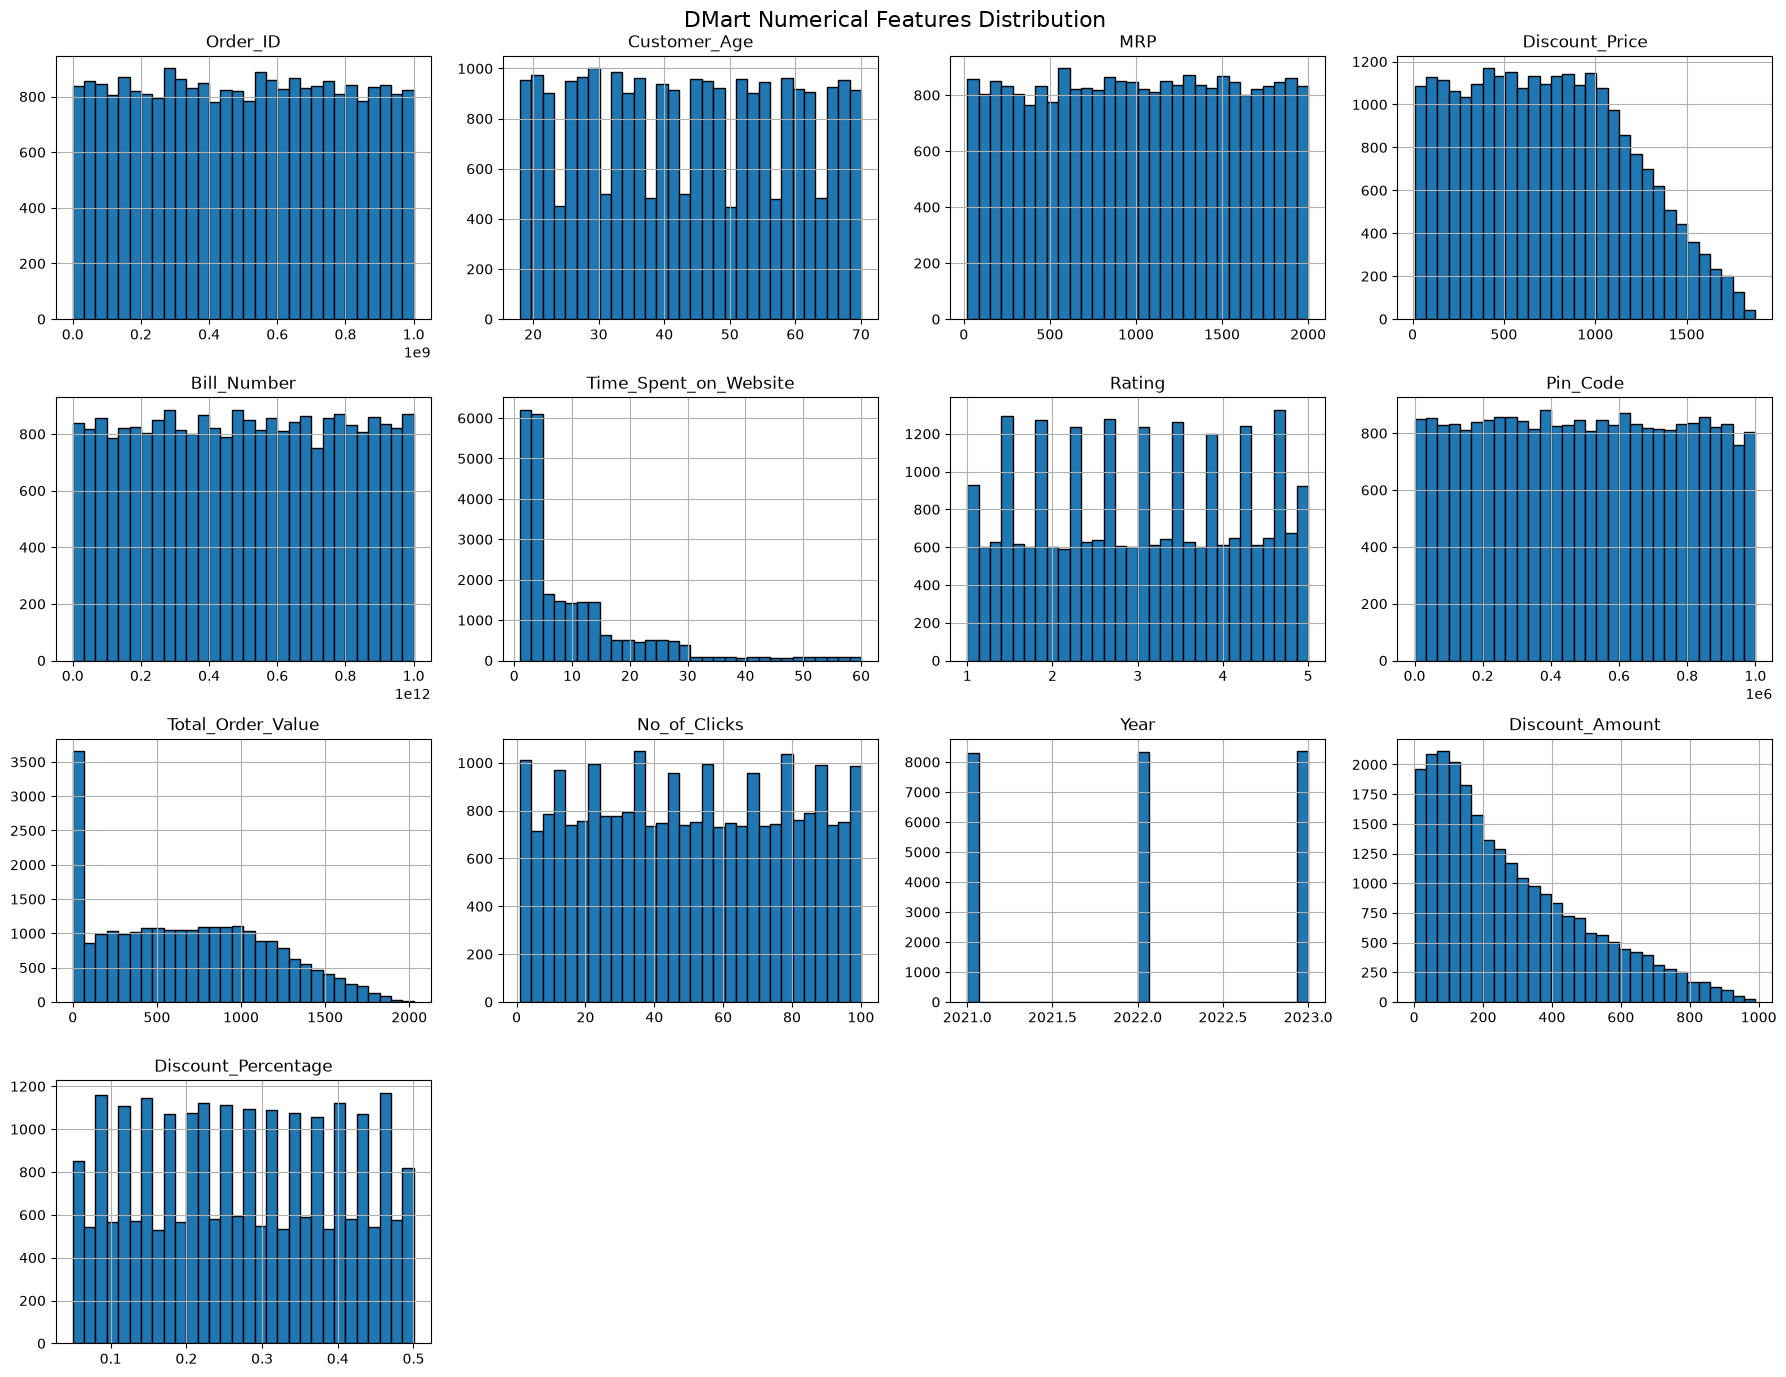

In [12]:
# Histograms of Numerical Features

numerical_data = df_clean.select_dtypes(include=np.number)

numerical_data.hist(
    figsize=(18, 14),
    bins=30,
    edgecolor="black"
)

plt.suptitle("DMart Numerical Features Distribution", fontsize=16)

plt.tight_layout()
plt.show()

In [13]:
# Outlier Detection Using IQR

numerical_features = [
    "Customer_Age",
    "MRP",
    "Discount_Price",
    "Time_Spent_on_Website",
    "Rating",
    "Total_Order_Value",
    "No_of_Clicks",
    "Discount_Amount",
    "Discount_Percentage"
]

outlier_results = []

for column in numerical_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    outlier_results.append({
        "Feature": column,
        "Lower_Limit": lower_limit,
        "Upper_Limit": upper_limit,
        "Outlier_Count": len(outliers)
    })

outlier_analysis = pd.DataFrame(outlier_results)

outlier_analysis

,Feature,Lower_Limit,Upper_Limit,Outlier_Count
0,Customer_Age,-8.00000,96.00000,0
1,MRP,-950.23125,2981.03875,0
2,Discount_Price,-672.85875,2101.87125,0
3,Time_Spent_on_Website,-12.69500,29.10500,1508
4,Rating,-1.00000,7.00000,0
5,Total_Order_Value,-943.14500,2238.99500,0
6,No_of_Clicks,-49.00000,151.00000,0
7,Discount_Amount,-365.20875,878.70125,212
8,Discount_Percentage,-0.18500,0.73500,0


In [14]:
# Inspect Outlier Values

time_outliers = df[
    df["Time_Spent_on_Website"] > 29.105
]

discount_outliers = df[
    df["Discount_Amount"] > 878.70125
]

print("Website Time Outliers:")
display(time_outliers[["Time_Spent_on_Website", "Order_Status"]].head(10))

print("\nDiscount Amount Outliers:")
display(discount_outliers[["MRP", "Discount_Price", "Discount_Amount"]].head(10))

print("\nMaximum Website Time:", df["Time_Spent_on_Website"].max())
print("Maximum Discount Amount:", df["Discount_Amount"].max())

Website Time Outliers:


,Time_Spent_on_Website,Order_Status
18,42.48,Delivered
28,55.23,Delivered
73,31.88,Delivered
100,52.11,Delivered
153,53.28,Delivered
159,29.63,Shipped
166,50.72,Returned
207,51.08,Delivered
211,44.60,Delivered
237,35.32,Shipped



Discount Amount Outliers:


,MRP,Discount_Price,Discount_Amount
92,1840.91,957.27,883.64
258,1869.66,972.22,897.44
557,1883.60,979.47,904.13
581,1939.91,1047.55,892.36
739,1981.11,1069.80,911.31
748,1827.53,932.04,895.49
768,1922.77,980.61,942.16
844,1973.03,1045.71,927.32
938,1899.86,949.93,949.93
1025,1902.05,989.07,912.98



Maximum Website Time: 59.97
Maximum Discount Amount: 990.45


In [15]:
# Create a separate dataset for outlier treatment

df_model = df.copy()

# Calculate IQR limits and cap outliers
for column in ["Time_Spent_on_Website", "Discount_Amount"]:

    Q1 = df_model[column].quantile(0.25)
    Q3 = df_model[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_model[column] = df_model[column].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outlier treatment completed!")

print("Original maximum website time:",
      df["Time_Spent_on_Website"].max())

print("Treated maximum website time:",
      df_model["Time_Spent_on_Website"].max())

print("Original maximum discount amount:",
      df["Discount_Amount"].max())

print("Treated maximum discount amount:",
      df_model["Discount_Amount"].max())

Outlier treatment completed!
Original maximum website time: 59.97
Treated maximum website time: 29.104999999999997
Original maximum discount amount: 990.45
Treated maximum discount amount: 878.7012500000001


In [16]:
# Statistical Analysis

numerical_columns = df_model.select_dtypes(
    include=np.number
).columns

statistics = pd.DataFrame({
    "Mean": df_model[numerical_columns].mean(),
    "Median": df_model[numerical_columns].median(),
    "Standard_Deviation": df_model[numerical_columns].std(),
    "Variance": df_model[numerical_columns].var()
})

display(statistics.round(2))

,Mean,Median,Standard_Deviation,Variance
Order_ID,4.987130e+08,4.997311e+08,2.881895e+08,8.305318e+16
Customer_Age,4.386000e+01,4.400000e+01,1.529000e+01,2.336500e+02
MRP,1.013750e+03,1.014420e+03,5.710800e+02,3.261320e+05
Discount_Price,7.356200e+02,7.131400e+02,4.413600e+02,1.948011e+05
Bill_Number,5.016695e+11,5.020000e+11,2.887202e+11,8.335938e+22
Time_Spent_on_Website,9.340000e+00,5.000000e+00,8.500000e+00,7.223000e+01
Rating,3.010000e+00,3.000000e+00,1.160000e+00,1.340000e+00
Pin_Code,4.967311e+05,4.952155e+05,2.877269e+05,8.278678e+10
Total_Order_Value,6.781600e+02,6.560400e+02,4.886300e+02,2.387586e+05
No_of_Clicks,5.042000e+01,5.000000e+01,2.887000e+01,8.333600e+02


In [17]:
# Select input features

features = [
    "Customer_Age",
    "MRP",
    "Discount_Price",
    "Time_Spent_on_Website",
    "Rating",
    "No_of_Clicks",
    "Discount_Amount",
    "Discount_Percentage"
]

X = df_model[features]

# Select target variable

y = df_model["Total_Order_Value"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

X Shape: (25000, 8)
y Shape: (25000,)

Input Features:
   Customer_Age      MRP  Discount_Price  Time_Spent_on_Website  Rating  \
0            28   977.44          909.02                   4.18     1.0   
1            47   834.09          450.41                   7.51     2.6   
2            63  1095.20         1007.58                   1.79     1.1   
3            41   748.16          389.04                   1.15     4.8   
4            22  1249.04          911.80                   1.31     1.4   

   No_of_Clicks  Discount_Amount  Discount_Percentage  
0            29            68.42                 0.07  
1            95           383.68                 0.46  
2            51            87.62                 0.08  
3            12           359.12                 0.48  
4            26           337.24                 0.27  

Target Values:
0     909.02
1     450.41
2    1007.58
3     489.04
4    1011.80
Name: Total_Order_Value, dtype: float64


In [18]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (20000, 8)
Testing Data Shape: (5000, 8)
Training Target Shape: (20000,)
Testing Target Shape: (5000,)


In [19]:
# Check Total Order Value Calculation

df_model[[
    "Discount_Price",
    "Shipping_Charges",
    "Total_Order_Value"
]].head(10)

,Discount_Price,Shipping_Charges,Total_Order_Value
0,909.02,0,909.02
1,450.41,0,450.41
2,1007.58,0,1007.58
3,389.04,100,489.04
4,911.80,100,1011.80
5,847.48,150,997.48
6,383.56,0,383.56
7,218.62,0,218.62
8,31.94,0,31.94
9,1138.24,100,1238.24


In [21]:
# Check Difference Between Actual and Calculated Values

difference = df_model["Total_Order_Value"] - (
    df_model["Discount_Price"] + df_model["Shipping_Charges"]
)

difference.describe()

TypeError: unsupported operand type(s) for +: 'float' and 'str'

In [22]:
# Check Column Data Types

print(df_model[[
    "Discount_Price",
    "Shipping_Charges",
    "Total_Order_Value"
]].dtypes)

print("\nShipping Charges Sample Values:")
print(df_model["Shipping_Charges"].unique()[:20])

Discount_Price       float64
Shipping_Charges      object
Total_Order_Value    float64
dtype: object

Shipping Charges Sample Values:
[0 100 150 'Cancelled' 25 75 50]


In [23]:
# Convert Shipping Charges to Numeric Values

shipping_numeric = pd.to_numeric(
    df_model["Shipping_Charges"],
    errors="coerce"
)

print("Missing or non-numeric shipping values:", shipping_numeric.isna().sum())
print("Non-numeric values:")
print(df_model.loc[shipping_numeric.isna(), "Shipping_Charges"].value_counts())

Missing or non-numeric shipping values: 1784
Non-numeric values:
Shipping_Charges
Cancelled    1784
Name: count, dtype: int64


In [24]:
# Compare Actual and Calculated Order Values

calculated_value = (
    df_model["Discount_Price"] + shipping_numeric
)

difference = df_model["Total_Order_Value"] - calculated_value

print(difference.describe())
print("\nFirst 10 comparisons:")
print(pd.DataFrame({
    "Actual_Value": df_model["Total_Order_Value"],
    "Calculated_Value": calculated_value,
    "Difference": difference
}).head(10))

count    2.321600e+04
mean    -4.588603e+01
std      2.127541e+02
min     -1.934230e+03
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.273737e-13
dtype: float64

First 10 comparisons:
   Actual_Value  Calculated_Value  Difference
0        909.02            909.02         0.0
1        450.41            450.41         0.0
2       1007.58           1007.58         0.0
3        489.04            489.04         0.0
4       1011.80           1011.80         0.0
5        997.48            997.48         0.0
6        383.56            383.56         0.0
7        218.62            218.62         0.0
8         31.94             31.94         0.0
9       1238.24           1238.24         0.0


In [25]:
# Compare Order Values for Non-Cancelled Orders

valid_rows = shipping_numeric.notna()

calculated_value = (
    df_model.loc[valid_rows, "Discount_Price"]
    + shipping_numeric.loc[valid_rows]
)

difference = (
    df_model.loc[valid_rows, "Total_Order_Value"]
    - calculated_value
)

print("Number of non-cancelled rows:", valid_rows.sum())
print("\nDifference Summary:")
print(difference.describe())

print("\nFirst 10 comparisons:")
print(pd.DataFrame({
    "Actual_Value": df_model.loc[valid_rows, "Total_Order_Value"],
    "Calculated_Value": calculated_value,
    "Difference": difference
}).head(10))

Number of non-cancelled rows: 23216

Difference Summary:
count    2.321600e+04
mean    -4.588603e+01
std      2.127541e+02
min     -1.934230e+03
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.273737e-13
dtype: float64

First 10 comparisons:
   Actual_Value  Calculated_Value  Difference
0        909.02            909.02         0.0
1        450.41            450.41         0.0
2       1007.58           1007.58         0.0
3        489.04            489.04         0.0
4       1011.80           1011.80         0.0
5        997.48            997.48         0.0
6        383.56            383.56         0.0
7        218.62            218.62         0.0
8         31.94             31.94         0.0
9       1238.24           1238.24         0.0


In [26]:
# Identify Rows Where the Formula Does Not Match

comparison = pd.DataFrame({
    "Discount_Price": df_model.loc[valid_rows, "Discount_Price"],
    "Shipping_Charges": shipping_numeric.loc[valid_rows],
    "Actual_Value": df_model.loc[valid_rows, "Total_Order_Value"],
    "Calculated_Value": calculated_value,
    "Difference": difference
})

exceptions = comparison[
    comparison["Difference"].abs() > 0.01
]

print("Number of exceptions:", len(exceptions))
exceptions.head(15)

Number of exceptions: 1350


,Discount_Price,Shipping_Charges,Actual_Value,Calculated_Value,Difference
24,281.06,25.0,0.0,306.06,-306.06
33,162.30,0.0,0.0,162.30,-162.30
36,1288.80,0.0,0.0,1288.80,-1288.80
41,1279.07,0.0,0.0,1279.07,-1279.07
50,1187.51,75.0,0.0,1262.51,-1262.51
77,349.87,100.0,0.0,449.87,-449.87
104,841.02,150.0,0.0,991.02,-991.02
154,698.09,75.0,0.0,773.09,-773.09
160,432.99,100.0,0.0,532.99,-532.99
166,1015.52,100.0,0.0,1115.52,-1115.52


In [27]:
# Investigate Zero-Value Orders

exception_indices = exceptions.index

df_model.loc[
    exception_indices,
    [
        "Order_ID",
        "Order_Status",
        "Payment_Status",
        "Discount_Price",
        "Shipping_Charges",
        "Total_Order_Value"
    ]
].head(20)

,Order_ID,Order_Status,Payment_Status,Discount_Price,Shipping_Charges,Total_Order_Value
24,185464676,Returned,Returned,281.06,25,0.0
33,689193131,Returned,Returned,162.30,0,0.0
36,619281679,Returned,Returned,1288.80,0,0.0
41,73119580,Returned,Returned,1279.07,0,0.0
50,224443733,Returned,Returned,1187.51,75,0.0
77,588442452,Returned,Returned,349.87,100,0.0
104,602452125,Returned,Returned,841.02,150,0.0
154,735197374,Returned,Returned,698.09,75,0.0
160,658350170,Returned,Returned,432.99,100,0.0
166,870176717,Returned,Returned,1015.52,100,0.0


In [28]:
# Count Order Status in Exceptions

df_model.loc[exception_indices, "Order_Status"].value_counts()

Order_Status
Returned    1350
Name: count, dtype: int64

In [29]:
# Check Order Status Distribution

print(df_model["Order_Status"].value_counts())

print("\nCategory Distribution:")
print(df_model["Category"].value_counts())

print("\nMarketing Advertisement Distribution:")
print(df_model["Marketing_Advertisement"].value_counts())

Order_Status
Delivered    13009
Shipped       8857
Cancelled     1784
Returned      1350
Name: count, dtype: int64

Category Distribution:
Category
Local       12402
Branded      7564
Imported     5034
Name: count, dtype: int64

Marketing Advertisement Distribution:
Marketing_Advertisement
Instagram    8520
Facebook     6252
Friends      4122
Other        4040
TV           2066
Name: count, dtype: int64


In [30]:
# Inspect Available Dataset Columns

print(df_model.columns.tolist())

['Customer_ID', 'Product_ID', 'Order_ID', 'Customer_Age', 'Gender', 'Product_Name', 'MRP', 'Discount_Price', 'Category', 'State', 'City', 'Subscription', 'Bill_Number', 'Time_Spent_on_Website', 'Rating', 'Marketing_Advertisement', 'Ship_Mode', 'Order_Status', 'Delivery_Date', 'Cancellation_Date', 'Payment_Method', 'Pin_Code', 'Total_Order_Value', 'Payment_Status', 'No_of_Clicks', 'Year', 'Month', 'Shipping_Charges', 'Discount_Amount', 'Discount_Percentage', 'Age_Group']


In [31]:
# Inspect Sample Data for Feature Selection

df_model[[
    "Customer_Age",
    "Gender",
    "Product_Name",
    "MRP",
    "Category",
    "State",
    "City",
    "Subscription",
    "Time_Spent_on_Website",
    "Rating",
    "Marketing_Advertisement",
    "Ship_Mode",
    "No_of_Clicks",
    "Total_Order_Value"
]].head(10)

,Customer_Age,Gender,Product_Name,MRP,Category,State,City,Subscription,Time_Spent_on_Website,Rating,Marketing_Advertisement,Ship_Mode,No_of_Clicks,Total_Order_Value
0,28,Female,Ariel Matic Top Load Liquid Detergent,977.44,Imported,Andhra Pradesh,Rajahmundry,Premium,4.18,1.0,Instagram,Free,29,909.02
1,47,Male,VSR Channa Dal,834.09,Branded,Telangana,Nalgonda,Freepass,7.51,2.6,Facebook,Free,95,450.41
2,63,Female,Tenali Double Horse Chana Dal,1095.20,Branded,Gujarat,Junagadh,Freepass,1.79,1.1,Instagram,Free,51,1007.58
3,41,Male,Tata Tea,748.16,Imported,Maharashtra,Nagpur,Freepass,1.15,4.8,Other,Priority,12,489.04
4,22,Female,VSR Channa Dal,1249.04,Local,Gujarat,Vadodara,Freepass,1.31,1.4,Other,Priority,26,1011.80
5,27,Male,Tata Tea,1661.72,Local,Gujarat,Bhavnagar,Freepass,9.76,1.9,Instagram,Express plus,91,997.48
6,42,Male,Sofit Soya Drink Vanilla,525.42,Branded,Maharashtra,Nashik,Premium,1.89,1.4,Instagram,Free,59,383.56
7,66,Female,Tata Sampann Chana Dal,412.50,Local,Gujarat,Vadodara,Premium,4.61,3.4,Friends,Free,100,218.62
8,50,Female,Sofit Soya Drink Vanilla,38.02,Imported,Telangana,Ramagundam,Premium,6.42,4.0,Facebook,Free,42,31.94
9,58,Female,Nutri Delite Breakfast Cereal,1422.80,Local,Maharashtra,Aurangabad,Freepass,13.76,3.4,Instagram,Priority,68,1238.24


In [32]:
# Select Regression Features

regression_features = [
    "Customer_Age",
    "Gender",
    "MRP",
    "Category",
    "Subscription",
    "Time_Spent_on_Website",
    "Rating",
    "Marketing_Advertisement",
    "Ship_Mode",
    "No_of_Clicks"
]

X_reg = df_model[regression_features].copy()
y_reg = df_model["Total_Order_Value"].copy()

print("Features Shape:", X_reg.shape)
print("Target Shape:", y_reg.shape)

X_reg.head()

Features Shape: (25000, 10)
Target Shape: (25000,)


,Customer_Age,Gender,MRP,Category,Subscription,Time_Spent_on_Website,Rating,Marketing_Advertisement,Ship_Mode,No_of_Clicks
0,28,Female,977.44,Imported,Premium,4.18,1.0,Instagram,Free,29
1,47,Male,834.09,Branded,Freepass,7.51,2.6,Facebook,Free,95
2,63,Female,1095.20,Branded,Freepass,1.79,1.1,Instagram,Free,51
3,41,Male,748.16,Imported,Freepass,1.15,4.8,Other,Priority,12
4,22,Female,1249.04,Local,Freepass,1.31,1.4,Other,Priority,26


In [33]:
# Convert Categorical Features into Numerical Features

X_reg_encoded = pd.get_dummies(
    X_reg,
    columns=[
        "Gender",
        "Category",
        "Subscription",
        "Marketing_Advertisement",
        "Ship_Mode"
    ],
    drop_first=True,
    dtype=int
)

print("Original Features Shape:", X_reg.shape)
print("Encoded Features Shape:", X_reg_encoded.shape)

X_reg_encoded.head()



Original Features Shape: (25000, 10)
Encoded Features Shape: (25000, 16)


,Customer_Age,MRP,Time_Spent_on_Website,Rating,No_of_Clicks,Gender_Male,Category_Imported,Category_Local,Subscription_Premium,Subscription_Premium Plus,Marketing_Advertisement_Friends,Marketing_Advertisement_Instagram,Marketing_Advertisement_Other,Marketing_Advertisement_TV,Ship_Mode_Free,Ship_Mode_Priority
0,28,977.44,4.18,1.0,29,0,1,0,1,0,0,1,0,0,1,0
1,47,834.09,7.51,2.6,95,1,0,0,0,0,0,0,0,0,1,0
2,63,1095.20,1.79,1.1,51,0,0,0,0,0,0,1,0,0,1,0
3,41,748.16,1.15,4.8,12,1,1,0,0,0,0,0,1,0,0,1
4,22,1249.04,1.31,1.4,26,0,0,1,0,0,0,0,1,0,0,1


In [34]:
# Split Regression Data

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg_encoded,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train_reg.shape)
print("Testing Features:", X_test_reg.shape)
print("Training Target:", y_train_reg.shape)
print("Testing Target:", y_test_reg.shape)

Training Features: (20000, 16)
Testing Features: (5000, 16)
Training Target: (20000,)
Testing Target: (5000,)


In [35]:
# Scale Regression Features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_reg)
X_test_scaled = scaler.transform(X_test_reg)

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Scaled Training Shape: (20000, 16)
Scaled Testing Shape: (5000, 16)


In [36]:
# Train Linear Regression Model

linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train_reg)

y_pred_linear = linear_model.predict(X_test_scaled)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [37]:
# Evaluate Linear Regression Model

mae_linear = mean_absolute_error(y_test_reg, y_pred_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_test_reg, y_pred_linear)
)

r2_linear = r2_score(y_test_reg, y_pred_linear)

print("Linear Regression Performance")
print("------------------------------")
print("MAE:", round(mae_linear, 2))
print("RMSE:", round(rmse_linear, 2))
print("R2 Score:", round(r2_linear, 4))

Linear Regression Performance
------------------------------
MAE: 203.72
RMSE: 324.11
R2 Score: 0.5603


In [38]:
# Train Ridge Regression Model

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train_reg)

y_pred_ridge = ridge_model.predict(X_test_scaled)

print("Ridge Regression Model Trained Successfully!")

Ridge Regression Model Trained Successfully!


In [39]:
# Evaluate Ridge Regression Model

mae_ridge = mean_absolute_error(y_test_reg, y_pred_ridge)

rmse_ridge = np.sqrt(
    mean_squared_error(y_test_reg, y_pred_ridge)
)

r2_ridge = r2_score(y_test_reg, y_pred_ridge)

print("Ridge Regression Performance")
print("----------------------------")
print("MAE:", round(mae_ridge, 2))
print("RMSE:", round(rmse_ridge, 2))
print("R2 Score:", round(r2_ridge, 4))

Ridge Regression Performance
----------------------------
MAE: 203.72
RMSE: 324.11
R2 Score: 0.5603


In [40]:
# Train Lasso Regression Model

lasso_model = Lasso(alpha=0.1, max_iter=10000)

lasso_model.fit(X_train_scaled, y_train_reg)

y_pred_lasso = lasso_model.predict(X_test_scaled)

print("Lasso Regression Model Trained Successfully!")

Lasso Regression Model Trained Successfully!


In [41]:
# Evaluate Lasso Regression Model

mae_lasso = mean_absolute_error(y_test_reg, y_pred_lasso)

rmse_lasso = np.sqrt(
    mean_squared_error(y_test_reg, y_pred_lasso)
)

r2_lasso = r2_score(y_test_reg, y_pred_lasso)

print("Lasso Regression Performance")
print("----------------------------")
print("MAE:", round(mae_lasso, 2))
print("RMSE:", round(rmse_lasso, 2))
print("R2 Score:", round(r2_lasso, 4))

Lasso Regression Performance
----------------------------
MAE: 203.72
RMSE: 324.11
R2 Score: 0.5603


In [42]:
# Compare Regression Models

regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MAE": [
        mae_linear,
        mae_ridge,
        mae_lasso
    ],
    "RMSE": [
        rmse_linear,
        rmse_ridge,
        rmse_lasso
    ],
    "R2 Score": [
        r2_linear,
        r2_ridge,
        r2_lasso
    ]
})

regression_results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,203.718863,324.108339,0.560336
1,Ridge Regression,203.719522,324.108564,0.560336
2,Lasso Regression,203.717496,324.107641,0.560338


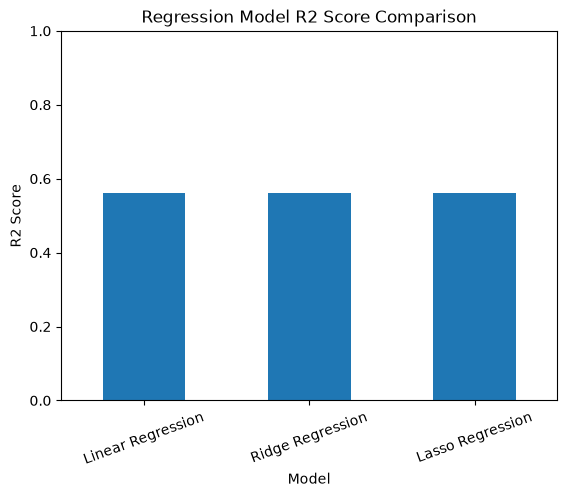

In [43]:
# Visualize Regression Model Comparison

regression_results.set_index("Model")[["R2 Score"]].plot(
    kind="bar",
    legend=False,
    title="Regression Model R2 Score Comparison"
)

plt.ylabel("R2 Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

In [44]:
# Create Polynomial Features

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print("Original Training Shape:", X_train_scaled.shape)
print("Polynomial Training Shape:", X_train_poly.shape)
print("Polynomial Testing Shape:", X_test_poly.shape)

Original Training Shape: (20000, 16)
Polynomial Training Shape: (20000, 152)
Polynomial Testing Shape: (5000, 152)


In [45]:
# Train Polynomial Regression Model

poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train_reg)

y_pred_poly = poly_model.predict(X_test_poly)

print("Polynomial Regression Model Trained Successfully!")

Polynomial Regression Model Trained Successfully!


In [46]:
# Evaluate Polynomial Regression Model

mae_poly = mean_absolute_error(y_test_reg, y_pred_poly)

rmse_poly = np.sqrt(
    mean_squared_error(y_test_reg, y_pred_poly)
)

r2_poly = r2_score(y_test_reg, y_pred_poly)

print("Polynomial Regression Performance")
print("----------------------------------")
print("MAE:", round(mae_poly, 2))
print("RMSE:", round(rmse_poly, 2))
print("R2 Score:", round(r2_poly, 4))


Polynomial Regression Performance
----------------------------------
MAE: 204.32
RMSE: 324.16
R2 Score: 0.5602


In [47]:
# Train Random Forest Regression Model

from sklearn.ensemble import RandomForestRegressor

rf_reg_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_reg_model.fit(X_train_reg, y_train_reg)

y_pred_rf = rf_reg_model.predict(X_test_reg)

print("Random Forest Regression Model Trained Successfully!")

Random Forest Regression Model Trained Successfully!


In [48]:
# Evaluate Random Forest Regression Model

mae_rf = mean_absolute_error(y_test_reg, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test_reg, y_pred_rf)
)

r2_rf = r2_score(y_test_reg, y_pred_rf)

print("Random Forest Regression Performance")
print("------------------------------------")
print("MAE:", round(mae_rf, 2))
print("RMSE:", round(rmse_rf, 2))
print("R2 Score:", round(r2_rf, 4))

Random Forest Regression Performance
------------------------------------
MAE: 218.71
RMSE: 336.45
R2 Score: 0.5262


In [49]:
# Compare Random Forest Training and Testing Performance

y_train_pred_rf = rf_reg_model.predict(X_train_reg)

train_r2_rf = r2_score(y_train_reg, y_train_pred_rf)
test_r2_rf = r2_score(y_test_reg, y_pred_rf)

print("Random Forest Training R2:", round(train_r2_rf, 4))
print("Random Forest Testing R2:", round(test_r2_rf, 4))

Random Forest Training R2: 0.933
Random Forest Testing R2: 0.5262


In [50]:
# Train Tuned Random Forest Regression

rf_tuned_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_tuned_model.fit(X_train_reg, y_train_reg)

y_pred_rf_tuned = rf_tuned_model.predict(X_test_reg)

print("Tuned Random Forest Model Trained Successfully!")

Tuned Random Forest Model Trained Successfully!


In [1]:
# Tuned Random Forest Training and Testing Performance

y_train_pred_rf_tuned = rf_tuned_model.predict(X_train_reg)

train_r2_tuned = r2_score(y_train_reg, y_train_pred_rf_tuned)
test_r2_tuned = r2_score(y_test_reg, y_pred_rf_tuned)

print("Tuned Random Forest Training R2:", round(train_r2_tuned, 4))
print("Tuned Random Forest Testing R2:", round(test_r2_tuned, 4))

NameError: name 'rf_tuned_model' is not defined

In [2]:
# Recreate and Train Tuned Random Forest

from sklearn.ensemble import RandomForestRegressor

rf_tuned_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_tuned_model.fit(X_train_reg, y_train_reg)

y_pred_rf_tuned = rf_tuned_model.predict(X_test_reg)

print("Tuned Random Forest Model Trained Successfully!")

NameError: name 'X_train_reg' is not defined

In [3]:
# Check Existing Regression Variables

variables_to_check = [
    "df_model",
    "X_reg",
    "X_reg_encoded",
    "X_train_reg",
    "X_test_reg",
    "y_train_reg",
    "y_test_reg",
    "scaler"
]

for variable in variables_to_check:
    print(variable, ":", variable in globals())

df_model : False
X_reg : False
X_reg_encoded : False
X_train_reg : False
X_test_reg : False
y_train_reg : False
y_test_reg : False
scaler : False


In [4]:
# Check Dataset and Imported Libraries

print("Dataset available:", "df" in globals())
print("Pandas available:", "pd" in globals())
print("NumPy available:", "np" in globals())
print("RandomForestRegressor available:", "RandomForestRegressor" in globals())

Dataset available: False
Pandas available: False
NumPy available: False
RandomForestRegressor available: True


In [5]:
# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

from sklearn.linear_model import (
    LinearRegression, Lasso, Ridge, LogisticRegression
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.svm import SVC

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
# Load DMart Excel Dataset

from tkinter import Tk, filedialog

root = Tk()
root.withdraw()

file_path = filedialog.askopenfilename(
    title="Select DMart Excel Dataset",
    filetypes=[("Excel Files", "*.xlsx")]
)

root.destroy()

df = pd.read_excel(file_path)

print("Dataset imported successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset imported successfully!
Dataset Shape: (25000, 31)


,Customer_ID,Product_ID,Order_ID,Customer_Age,Gender,Product_Name,MRP,Discount_Price,Category,State,...,Pin_Code,Total_Order_Value,Payment_Status,No_of_Clicks,Year,Month,Shipping_Charges,Discount_Amount,Discount_Percentage,Age_Group
0,YSB75,BW653,479577309,28,Female,Ariel Matic Top Load Liquid Detergent,977.44,909.02,Imported,Andhra Pradesh,...,318324,909.02,Paid,29,2022,May,0,68.42,0.07,25-34
1,FUS93,XV061,634865221,47,Male,VSR Channa Dal,834.09,450.41,Branded,Telangana,...,730162,450.41,Paid,95,2021,August,0,383.68,0.46,45-54
2,AJP28,GF695,113166210,63,Female,Tenali Double Horse Chana Dal,1095.20,1007.58,Branded,Gujarat,...,694091,1007.58,Paid,51,2021,October,0,87.62,0.08,55+
3,URC55,VM478,740539230,41,Male,Tata Tea,748.16,389.04,Imported,Maharashtra,...,211807,489.04,Pending,12,2021,August,100,359.12,0.48,35-44
4,ZOP23,XD230,156544145,22,Female,VSR Channa Dal,1249.04,911.80,Local,Gujarat,...,78304,1011.80,Paid,26,2023,December,100,337.24,0.27,18-24


In [7]:
# Recreate Cleaned Modelling Dataset

df_clean = df.copy()

df_clean["Payment_Method"] = df_clean["Payment_Method"].fillna("Unknown")

df_model = df_clean.copy()

for column in ["Time_Spent_on_Website", "Discount_Amount"]:
    Q1 = df_model[column].quantile(0.25)
    Q3 = df_model[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_model[column] = df_model[column].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Modelling dataset recreated successfully!")
print("Dataset Shape:", df_model.shape)

Modelling dataset recreated successfully!
Dataset Shape: (25000, 31)


In [8]:
# Select Regression Features and Target

regression_features = [
    "Customer_Age",
    "Gender",
    "MRP",
    "Category",
    "Subscription",
    "Time_Spent_on_Website",
    "Rating",
    "Marketing_Advertisement",
    "Ship_Mode",
    "No_of_Clicks"
]

X_reg = df_model[regression_features].copy()

y_reg = df_model["Total_Order_Value"].copy()

print("Regression features recreated!")
print("X Shape:", X_reg.shape)
print("Y Shape:", y_reg.shape)

Regression features recreated!
X Shape: (25000, 10)
Y Shape: (25000,)


In [9]:
# One-Hot Encoding

X_reg_encoded = pd.get_dummies(
    X_reg,
    columns=[
        "Gender",
        "Category",
        "Subscription",
        "Marketing_Advertisement",
        "Ship_Mode"
    ],
    drop_first=True,
    dtype=int
)

print("Encoding completed successfully!")
print("Encoded Dataset Shape:", X_reg_encoded.shape)

X_reg_encoded.head()

Encoding completed successfully!
Encoded Dataset Shape: (25000, 16)


,Customer_Age,MRP,Time_Spent_on_Website,Rating,No_of_Clicks,Gender_Male,Category_Imported,Category_Local,Subscription_Premium,Subscription_Premium Plus,Marketing_Advertisement_Friends,Marketing_Advertisement_Instagram,Marketing_Advertisement_Other,Marketing_Advertisement_TV,Ship_Mode_Free,Ship_Mode_Priority
0,28,977.44,4.18,1.0,29,0,1,0,1,0,0,1,0,0,1,0
1,47,834.09,7.51,2.6,95,1,0,0,0,0,0,0,0,0,1,0
2,63,1095.20,1.79,1.1,51,0,0,0,0,0,0,1,0,0,1,0
3,41,748.16,1.15,4.8,12,1,1,0,0,0,0,0,1,0,0,1
4,22,1249.04,1.31,1.4,26,0,0,1,0,0,0,0,1,0,0,1


In [10]:
# Train-Test Split

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg_encoded,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Train-Test Split Completed!")
print("Training Features:", X_train_reg.shape)
print("Testing Features:", X_test_reg.shape)
print("Training Target:", y_train_reg.shape)
print("Testing Target:", y_test_reg.shape)

Train-Test Split Completed!
Training Features: (20000, 16)
Testing Features: (5000, 16)
Training Target: (20000,)
Testing Target: (5000,)


In [11]:
# Standardize Regression Features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_reg)

X_test_scaled = scaler.transform(X_test_reg)

print("Feature Scaling Completed!")
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Feature Scaling Completed!
Scaled Training Shape: (20000, 16)
Scaled Testing Shape: (5000, 16)


In [12]:
# Tuned Random Forest Regression

rf_tuned_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_tuned_model.fit(X_train_reg, y_train_reg)

y_pred_rf_tuned = rf_tuned_model.predict(X_test_reg)

print("Tuned Random Forest Model Trained Successfully!")

Tuned Random Forest Model Trained Successfully!


In [13]:
# Tuned Random Forest Performance Evaluation

y_train_pred_rf_tuned = rf_tuned_model.predict(X_train_reg)

train_r2_tuned = r2_score(y_train_reg, y_train_pred_rf_tuned)
test_r2_tuned = r2_score(y_test_reg, y_pred_rf_tuned)

print("Tuned Random Forest Training R2:", round(train_r2_tuned, 4))
print("Tuned Random Forest Testing R2:", round(test_r2_tuned, 4))
print("R2 Score Difference:", round(train_r2_tuned - test_r2_tuned, 4))

Tuned Random Forest Training R2: 0.6512
Tuned Random Forest Testing R2: 0.5502
R2 Score Difference: 0.1011


In [14]:
# Check XGBoost Installation

try:
    import xgboost as xgb
    print("XGBoost Version:", xgb.__version__)
    print("XGBoost is ready!")
except ImportError:
    print("XGBoost is not installed.")

XGBoost is not installed.


In [15]:
# Install XGBoost

%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/48.9 MB 4.4 MB/s eta 0:00:11
   - -------------------------------------- 2.4/48.9 MB 5.0 MB/s eta 0:00:10
   -- ------------------------------------- 3.4/48.9 MB 4.8 MB/s eta 0:00:10
   --- ------------------------------------ 4.5/48.9 MB 5.0 MB/s eta 0:00:09
   ---- ----------------------------------- 5.5/48.9 MB 5.1 MB/s eta 0:00:09
   ----- ---------------------------------- 6.6/48.9 MB 4.9 MB/s eta 0:00:09
   ------ --------------------------------- 7.6/48.9 MB 5.1 MB/s eta 0:00:09
   ------- -------------------------------- 8.9/48.9 MB 5.2 MB/s eta 0:00:08
   -------- ------------------------------- 10.0/48.9 MB 5.2 MB/s eta 0:00:08
   --------- ------------------------------ 11.3/48.9 MB 5.3 MB/s eta 0:00:08
   -------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
# Verify XGBoost Installation

import xgboost as xgb

print("XGBoost Version:", xgb.__version__)
print("XGBoost imported successfully!")


XGBoost Version: 3.4.1
XGBoost imported successfully!


In [17]:
# XGBoost Regression Model

from xgboost import XGBRegressor

xgb_reg_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror",
    n_jobs=-1
)

xgb_reg_model.fit(X_train_reg, y_train_reg)

y_pred_xgb = xgb_reg_model.predict(X_test_reg)

print("XGBoost Regression Model Trained Successfully!")

XGBoost Regression Model Trained Successfully!


In [18]:
# XGBoost Regression Performance

mae_xgb = mean_absolute_error(y_test_reg, y_pred_xgb)

rmse_xgb = np.sqrt(mean_squared_error(y_test_reg, y_pred_xgb))

r2_xgb = r2_score(y_test_reg, y_pred_xgb)

print("XGBoost Regression Performance")
print("--------------------------------")
print("MAE:", round(mae_xgb, 2))
print("RMSE:", round(rmse_xgb, 2))
print("R2 Score:", round(r2_xgb, 4))

XGBoost Regression Performance
--------------------------------
MAE: 205.76
RMSE: 327.01
R2 Score: 0.5524


In [19]:
# Regression Model Comparison

regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Polynomial Regression",
        "Random Forest Original",
        "Random Forest Tuned",
        "XGBoost"
    ],
    "MAE": [
        203.72, 203.72, 203.72, 204.32,
        218.71,
        mean_absolute_error(y_test_reg, y_pred_rf_tuned),
        mae_xgb
    ],
    "RMSE": [
        324.11, 324.11, 324.11, 324.16,
        336.45,
        np.sqrt(mean_squared_error(y_test_reg, y_pred_rf_tuned)),
        rmse_xgb
    ],
    "R2 Score": [
        0.5603, 0.5603, 0.5603, 0.5602,
        0.5262, test_r2_tuned, r2_xgb
    ]
})

regression_results = regression_results.sort_values(
    by="R2 Score", ascending=False
).reset_index(drop=True)

regression_results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,203.720000,324.110000,0.560300
1,Ridge Regression,203.720000,324.110000,0.560300
2,Lasso Regression,203.720000,324.110000,0.560300
3,Polynomial Regression,204.320000,324.160000,0.560200
4,XGBoost,205.760719,327.005297,0.552442
5,Random Forest Tuned,207.101820,327.836259,0.550164
6,Random Forest Original,218.710000,336.450000,0.526200


In [20]:
# Create Classification Target

df_model["Cancelled"] = (
    df_model["Order_Status"] == "Cancelled"
).astype(int)

print("Classification Target Created!")
print(df_model["Cancelled"].value_counts())
print("\nCancellation Distribution:")
print(df_model["Cancelled"].value_counts(normalize=True) * 100)

Classification Target Created!
Cancelled
0    23216
1     1784
Name: count, dtype: int64

Cancellation Distribution:
Cancelled
0    92.864
1     7.136
Name: proportion, dtype: float64


In [21]:
# Select Classification Features and Target

classification_features = [
    "Customer_Age",
    "Gender",
    "MRP",
    "Category",
    "Subscription",
    "Time_Spent_on_Website",
    "Rating",
    "Marketing_Advertisement",
    "Ship_Mode",
    "No_of_Clicks"
]

X_clf = df_model[classification_features].copy()

y_clf = df_model["Cancelled"].copy()

print("Classification Features:", X_clf.shape)
print("Classification Target:", y_clf.shape)
print("Features selected successfully!")

Classification Features: (25000, 10)
Classification Target: (25000,)
Features selected successfully!


In [22]:
# Classification One-Hot Encoding

X_clf_encoded = pd.get_dummies(
    X_clf,
    columns=[
        "Gender",
        "Category",
        "Subscription",
        "Marketing_Advertisement",
        "Ship_Mode"
    ],
    drop_first=True,
    dtype=int
)

print("Classification Encoding Completed!")
print("Encoded Dataset Shape:", X_clf_encoded.shape)

X_clf_encoded.head()

Classification Encoding Completed!
Encoded Dataset Shape: (25000, 16)


,Customer_Age,MRP,Time_Spent_on_Website,Rating,No_of_Clicks,Gender_Male,Category_Imported,Category_Local,Subscription_Premium,Subscription_Premium Plus,Marketing_Advertisement_Friends,Marketing_Advertisement_Instagram,Marketing_Advertisement_Other,Marketing_Advertisement_TV,Ship_Mode_Free,Ship_Mode_Priority
0,28,977.44,4.18,1.0,29,0,1,0,1,0,0,1,0,0,1,0
1,47,834.09,7.51,2.6,95,1,0,0,0,0,0,0,0,0,1,0
2,63,1095.20,1.79,1.1,51,0,0,0,0,0,0,1,0,0,1,0
3,41,748.16,1.15,4.8,12,1,1,0,0,0,0,0,1,0,0,1
4,22,1249.04,1.31,1.4,26,0,0,1,0,0,0,0,1,0,0,1


In [23]:
# Classification Train-Test Split

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf_encoded,
    y_clf,
    test_size=0.20,
    random_state=42,
    stratify=y_clf
)

print("Classification Train-Test Split Completed!")

print("Training Features:", X_train_clf.shape)
print("Testing Features:", X_test_clf.shape)

print("\nTraining Cancellation Distribution:")
print(y_train_clf.value_counts())

print("\nTesting Cancellation Distribution:")
print(y_test_clf.value_counts())

Classification Train-Test Split Completed!
Training Features: (20000, 16)
Testing Features: (5000, 16)

Training Cancellation Distribution:
Cancelled
0    18573
1     1427
Name: count, dtype: int64

Testing Cancellation Distribution:
Cancelled
0    4643
1     357
Name: count, dtype: int64


In [24]:
# Scale Classification Features

scaler_clf = StandardScaler()

X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)

X_test_clf_scaled = scaler_clf.transform(X_test_clf)

print("Classification Feature Scaling Completed!")
print("Training Shape:", X_train_clf_scaled.shape)
print("Testing Shape:", X_test_clf_scaled.shape)

Classification Feature Scaling Completed!
Training Shape: (20000, 16)
Testing Shape: (5000, 16)


In [25]:
# Logistic Regression Classifier

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_clf_scaled, y_train_clf)

y_pred_logistic = logistic_model.predict(X_test_clf_scaled)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [26]:
# Logistic Regression Performance Evaluation

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test_clf, y_pred_logistic)
precision = precision_score(y_test_clf, y_pred_logistic)
recall = recall_score(y_test_clf, y_pred_logistic)
f1 = f1_score(y_test_clf, y_pred_logistic)
roc_auc = roc_auc_score(
    y_test_clf,
    logistic_model.predict_proba(X_test_clf_scaled)[:, 1]
)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

Logistic Regression Performance
--------------------------------
Accuracy: 0.4956
Precision: 0.0709
Recall: 0.5014
F1 Score: 0.1243
ROC-AUC: 0.4861


In [27]:
# Decision Tree Classifier

decision_tree_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

decision_tree_model.fit(X_train_clf, y_train_clf)

y_pred_tree = decision_tree_model.predict(X_test_clf)

print("Decision Tree Classifier Trained Successfully!")

Decision Tree Classifier Trained Successfully!


In [28]:
# Decision Tree Performance

accuracy_tree = accuracy_score(y_test_clf, y_pred_tree)
precision_tree = precision_score(y_test_clf, y_pred_tree, zero_division=0)
recall_tree = recall_score(y_test_clf, y_pred_tree, zero_division=0)
f1_tree = f1_score(y_test_clf, y_pred_tree, zero_division=0)
roc_auc_tree = roc_auc_score(
    y_test_clf,
    decision_tree_model.predict_proba(X_test_clf)[:, 1]
)

print("Decision Tree Classifier Performance")
print("------------------------------------")
print("Accuracy:", round(accuracy_tree, 4))
print("Precision:", round(precision_tree, 4))
print("Recall:", round(recall_tree, 4))
print("F1 Score:", round(f1_tree, 4))
print("ROC-AUC:", round(roc_auc_tree, 4))

Decision Tree Classifier Performance
------------------------------------
Accuracy: 0.4076
Precision: 0.07
Recall: 0.5938
F1 Score: 0.1252
ROC-AUC: 0.5028


In [29]:
# Random Forest Classifier

rf_clf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_clf_model.fit(X_train_clf, y_train_clf)

y_pred_rf_clf = rf_clf_model.predict(X_test_clf)

print("Random Forest Classifier Trained Successfully!")

Random Forest Classifier Trained Successfully!


In [30]:
# Random Forest Performance

accuracy_rf_clf = accuracy_score(y_test_clf, y_pred_rf_clf)
precision_rf_clf = precision_score(y_test_clf, y_pred_rf_clf, zero_division=0)
recall_rf_clf = recall_score(y_test_clf, y_pred_rf_clf, zero_division=0)
f1_rf_clf = f1_score(y_test_clf, y_pred_rf_clf, zero_division=0)
roc_auc_rf_clf = roc_auc_score(
    y_test_clf,
    rf_clf_model.predict_proba(X_test_clf)[:, 1]
)

print("Random Forest Classifier Performance")
print("------------------------------------")
print("Accuracy:", round(accuracy_rf_clf, 4))
print("Precision:", round(precision_rf_clf, 4))
print("Recall:", round(recall_rf_clf, 4))
print("F1 Score:", round(f1_rf_clf, 4))
print("ROC-AUC:", round(roc_auc_rf_clf, 4))

Random Forest Classifier Performance
------------------------------------
Accuracy: 0.8378
Precision: 0.0858
Recall: 0.1317
F1 Score: 0.1039
ROC-AUC: 0.4926


In [33]:
# Support Vector Machine Classifier

svm_model = SVC(
    kernel="rbf",
    class_weight="balanced",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_clf_scaled, y_train_clf)

y_pred_svm = svm_model.predict(X_test_clf_scaled)

print("SVM Classifier Trained Successfully!")

SVM Classifier Trained Successfully!


In [34]:
# SVM Performance

accuracy_svm = accuracy_score(y_test_clf, y_pred_svm)
precision_svm = precision_score(y_test_clf, y_pred_svm, zero_division=0)
recall_svm = recall_score(y_test_clf, y_pred_svm, zero_division=0)
f1_svm = f1_score(y_test_clf, y_pred_svm, zero_division=0)

svm_scores = svm_model.decision_function(X_test_clf_scaled)
roc_auc_svm = roc_auc_score(y_test_clf, svm_scores)

print("SVM Classifier Performance")
print("--------------------------")
print("Accuracy:", round(accuracy_svm, 4))
print("Precision:", round(precision_svm, 4))
print("Recall:", round(recall_svm, 4))
print("F1 Score:", round(f1_svm, 4))
print("ROC-AUC:", round(roc_auc_svm, 4))

SVM Classifier Performance
--------------------------
Accuracy: 0.5792
Precision: 0.0745
Recall: 0.4286
F1 Score: 0.127
ROC-AUC: 0.4986


In [35]:
# XGBoost Classifier

from xgboost import XGBClassifier

xgb_clf_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=18573 / 1427,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_clf_model.fit(X_train_clf, y_train_clf)

y_pred_xgb_clf = xgb_clf_model.predict(X_test_clf)

print("XGBoost Classifier Trained Successfully!")

XGBoost Classifier Trained Successfully!


In [36]:
# XGBoost Classifier Performance

accuracy_xgb = accuracy_score(y_test_clf, y_pred_xgb_clf)
precision_xgb = precision_score(y_test_clf, y_pred_xgb_clf, zero_division=0)
recall_xgb = recall_score(y_test_clf, y_pred_xgb_clf, zero_division=0)
f1_xgb = f1_score(y_test_clf, y_pred_xgb_clf, zero_division=0)

roc_auc_xgb = roc_auc_score(
    y_test_clf,
    xgb_clf_model.predict_proba(X_test_clf)[:, 1]
)

print("XGBoost Classifier Performance")
print("--------------------------------")
print("Accuracy:", round(accuracy_xgb, 4))
print("Precision:", round(precision_xgb, 4))
print("Recall:", round(recall_xgb, 4))
print("F1 Score:", round(f1_xgb, 4))
print("ROC-AUC:", round(roc_auc_xgb, 4))

XGBoost Classifier Performance
--------------------------------
Accuracy: 0.6672
Precision: 0.0732
Recall: 0.3137
F1 Score: 0.1186
ROC-AUC: 0.4936


In [37]:
# Classification Model Comparison

classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test_clf, y_pred_logistic),
        accuracy_tree,
        accuracy_rf_clf,
        accuracy_svm,
        accuracy_xgb
    ],
    "Precision": [
        precision_score(y_test_clf, y_pred_logistic, zero_division=0),
        precision_tree,
        precision_rf_clf,
        precision_svm,
        precision_xgb
    ],
    "Recall": [
        recall_score(y_test_clf, y_pred_logistic, zero_division=0),
        recall_tree,
        recall_rf_clf,
        recall_svm,
        recall_xgb
    ],
    "F1 Score": [
        f1_score(y_test_clf, y_pred_logistic, zero_division=0),
        f1_tree,
        f1_rf_clf,
        f1_svm,
        f1_xgb
    ],
    "ROC-AUC": [
        roc_auc_score(y_test_clf, logistic_model.predict_proba(X_test_clf_scaled)[:, 1]),
        roc_auc_tree,
        roc_auc_rf_clf,
        roc_auc_svm,
        roc_auc_xgb
    ]
})

classification_results = classification_results.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

classification_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,SVM,0.5792,0.0745,0.4286,0.1270,0.4986
1,Decision Tree,0.4076,0.0700,0.5938,0.1252,0.5028
2,Logistic Regression,0.4956,0.0709,0.5014,0.1243,0.4861
3,XGBoost,0.6672,0.0732,0.3137,0.1186,0.4936
4,Random Forest,0.8378,0.0858,0.1317,0.1039,0.4926


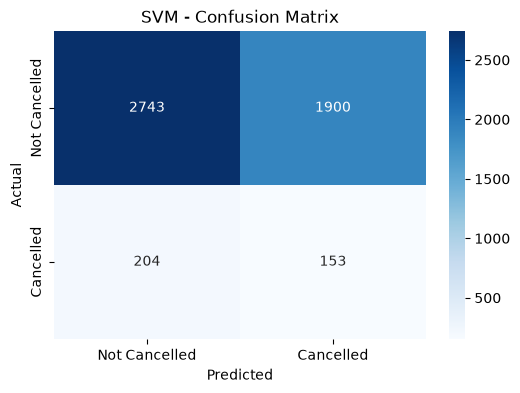

Classification Report
               precision    recall  f1-score   support

Not Cancelled       0.93      0.59      0.72      4643
    Cancelled       0.07      0.43      0.13       357

     accuracy                           0.58      5000
    macro avg       0.50      0.51      0.42      5000
 weighted avg       0.87      0.58      0.68      5000



In [38]:
# SVM Confusion Matrix

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

cm_svm = confusion_matrix(y_test_clf, y_pred_svm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Cancelled", "Cancelled"],
    yticklabels=["Not Cancelled", "Cancelled"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM - Confusion Matrix")
plt.show()

print("Classification Report")
print(classification_report(
    y_test_clf,
    y_pred_svm,
    target_names=["Not Cancelled", "Cancelled"],
    zero_division=0
))

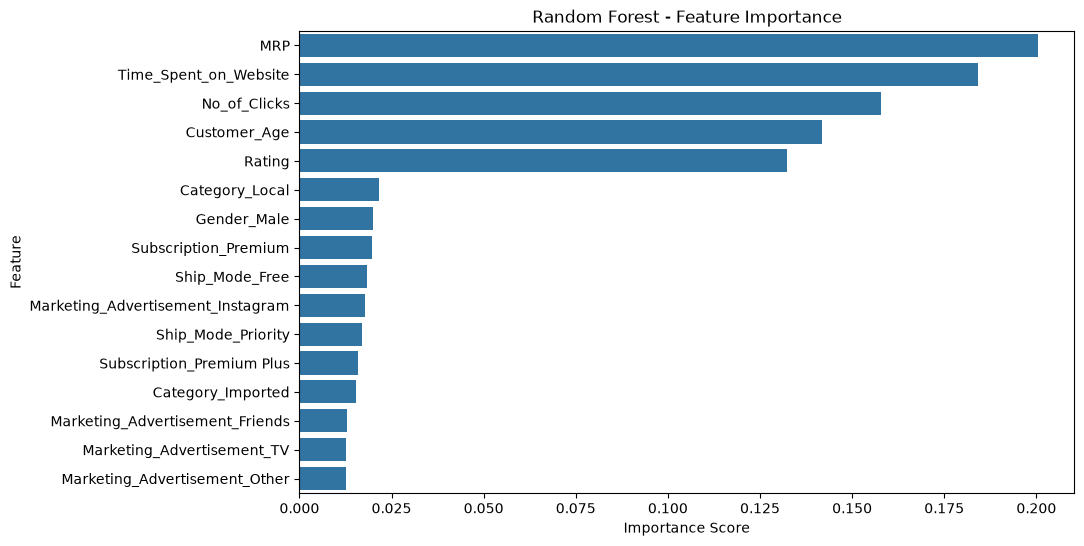

,Feature,Importance
1,MRP,0.200309
2,Time_Spent_on_Website,0.184121
4,No_of_Clicks,0.157837
0,Customer_Age,0.141792
3,Rating,0.132348
7,Category_Local,0.021543
5,Gender_Male,0.020006
8,Subscription_Premium,0.019707
14,Ship_Mode_Free,0.018282
11,Marketing_Advertisement_Instagram,0.017902


In [39]:
# Random Forest Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train_clf.columns,
    "Importance": rf_clf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

feature_importance

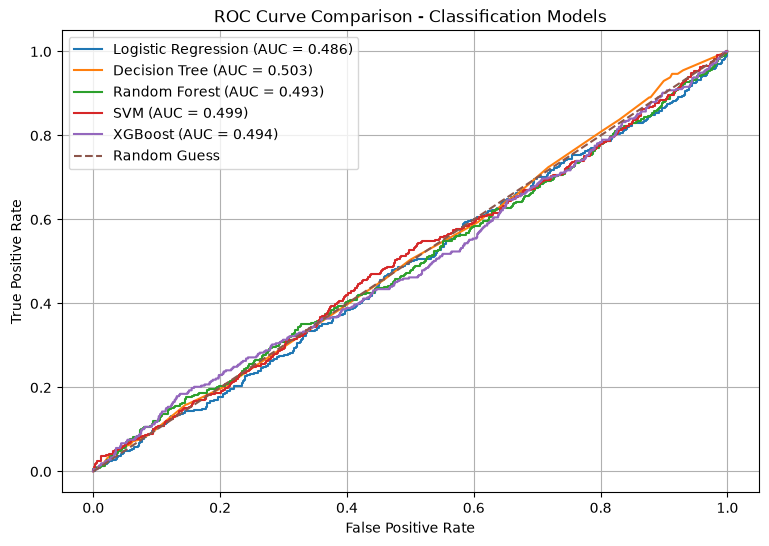

In [40]:
# ROC Curve Comparison

from sklearn.metrics import roc_curve, auc

roc_data = {
    "Logistic Regression": (
        y_test_clf,
        logistic_model.predict_proba(X_test_clf_scaled)[:, 1]
    ),
    "Decision Tree": (
        y_test_clf,
        decision_tree_model.predict_proba(X_test_clf)[:, 1]
    ),
    "Random Forest": (
        y_test_clf,
        rf_clf_model.predict_proba(X_test_clf)[:, 1]
    ),
    "SVM": (
        y_test_clf,
        svm_model.decision_function(X_test_clf_scaled)
    ),
    "XGBoost": (
        y_test_clf,
        xgb_clf_model.predict_proba(X_test_clf)[:, 1]
    )
}

plt.figure(figsize=(9, 6))

for model_name, (actual, scores) in roc_data.items():
    fpr, tpr, thresholds = roc_curve(actual, scores)
    roc_score = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Classification Models")
plt.legend()
plt.grid()
plt.show()

In [41]:
# Save Machine Learning Models

import os
import joblib

os.makedirs("../Models", exist_ok=True)

models_to_save = {
    "linear_regression.pkl": linear_model,
    "ridge_regression.pkl": ridge_model,
    "lasso_regression.pkl": lasso_model,
    "polynomial_regression.pkl": polynomial_model,
    "random_forest_regression.pkl": rf_model,
    "tuned_random_forest_regression.pkl": rf_tuned_model,
    "xgboost_regression.pkl": xgb_reg_model,
    "logistic_regression.pkl": logistic_model,
    "decision_tree_classifier.pkl": decision_tree_model,
    "random_forest_classifier.pkl": rf_clf_model,
    "svm_classifier.pkl": svm_model,
    "xgboost_classifier.pkl": xgb_clf_model
}

for filename, model in models_to_save.items():
    joblib.dump(model, f"../Models/{filename}")

print("All machine learning models saved successfully!")
print("Total models saved:", len(models_to_save))

NameError: name 'linear_model' is not defined

In [42]:
# Identify Trained Machine Learning Models

model_variables = [
    name for name, obj in globals().items()
    if hasattr(obj, "fit") and hasattr(obj, "predict")
]

print("Available trained model variables:")
for name in model_variables:
    print(name)

Available trained model variables:
RandomForestRegressor
rf_tuned_model
LinearRegression
Lasso
Ridge
LogisticRegression
DecisionTreeClassifier
RandomForestClassifier
SVC
XGBRegressor
xgb_reg_model
logistic_model
decision_tree_model
rf_clf_model
svm_model
XGBClassifier
xgb_clf_model


In [43]:
# Save Machine Learning Models

import os
import joblib

os.makedirs("../Models", exist_ok=True)

models_to_save = {
    "tuned_random_forest_regression.pkl": rf_tuned_model,
    "xgboost_regression.pkl": xgb_reg_model,
    "logistic_regression.pkl": logistic_model,
    "decision_tree_classifier.pkl": decision_tree_model,
    "random_forest_classifier.pkl": rf_clf_model,
    "svm_classifier.pkl": svm_model,
    "xgboost_classifier.pkl": xgb_clf_model
}

for filename, model in models_to_save.items():
    joblib.dump(model, f"../Models/{filename}")

print("All selected machine learning models saved successfully!")
print("Total models saved:", len(models_to_save))

All selected machine learning models saved successfully!
Total models saved: 7


In [44]:
# Save Preprocessing Objects and Feature Columns

preprocessing_objects = {
    "regression_scaler.pkl": scaler,
    "classification_scaler.pkl": scaler_clf,
    "regression_feature_columns.pkl": list(X_train_reg.columns),
    "classification_feature_columns.pkl": list(X_train_clf.columns)
}

for filename, obj in preprocessing_objects.items():
    joblib.dump(obj, f"../Models/{filename}")

print("Preprocessing objects saved successfully!")
print("Total preprocessing files saved:", len(preprocessing_objects))

Preprocessing objects saved successfully!
Total preprocessing files saved: 4


In [45]:
# Verify Saved Model Files

import os

model_folder = "../Models"

saved_files = os.listdir(model_folder)

print("Saved Files in Models Folder")
print("-----------------------------")

for file in sorted(saved_files):
    print("✓", file)

print("\nTotal files saved:", len(saved_files))

Saved Files in Models Folder
-----------------------------
✓ classification_feature_columns.pkl
✓ classification_scaler.pkl
✓ decision_tree_classifier.pkl
✓ logistic_regression.pkl
✓ random_forest_classifier.pkl
✓ regression_feature_columns.pkl
✓ regression_scaler.pkl
✓ svm_classifier.pkl
✓ tuned_random_forest_regression.pkl
✓ xgboost_classifier.pkl
✓ xgboost_regression.pkl

Total files saved: 11


In [46]:
%pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.2 MB 5.7 MB/s eta 0:00:02
   ----- ---------------------------------- 1.6/11.2 MB 4.7 MB/s eta 0:00:03
   ------- -------------------------------- 2.1/11.2 MB 4.4 MB/s eta 0:00:03
   ----------- ---------------------------- 3.1/11.2 MB 4.1 MB/s eta 0:00:02
   ------------- -------------------------- 3.9/11.2 MB 4.4 MB/s eta 0:00:02
   ----------------- ---------------------- 5.0/11.2 MB 4.2 MB/s eta 0:00:02
   ------------------- -------------------- 5.5/11.2 MB 4.0 MB/s eta 0:00:02
   ----------------------- ---------------- 6.6/11.2 MB 4.1 MB/s eta 0:00:02
   --------------------------- ------------ 7.6/11.2 MB 4.3 MB/s eta 0:00:01
   ------------------------------ --------- 8.7/11.2 MB 4.4 MB/s eta 0:00:01
   ---------------------------------- ----- 9.7/11.2 MB 4.4 MB/s eta 0:00:01
   --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
import streamlit as st

print("Streamlit version:", st.__version__)
print("Streamlit installed successfully!")

Streamlit version: 1.67.0
Streamlit installed successfully!


In [48]:
import os

project_path = r"C:\Users\burha\Documents\DMart_Python_Data_Analysis"

os.makedirs(project_path, exist_ok=True)
os.makedirs(os.path.join(project_path, "Models"), exist_ok=True)

print("Project folders verified successfully!")
print(project_path)


Project folders verified successfully!
C:\Users\burha\Documents\DMart_Python_Data_Analysis


In [49]:
import os

models_path = r"C:\Users\burha\Documents\DMart_Python_Data_Analysis\Models"

print("Models folder exists:", os.path.exists(models_path))
print("\nFiles found:")

for file in sorted(os.listdir(models_path)):
    print(file)

print("\nTotal files:", len(os.listdir(models_path)))

Models folder exists: True

Files found:

Total files: 0


In [1]:
# Check Current Project Location

import os

print("Current Working Directory:")
print(os.getcwd())

print("\nModels Folder Location:")
print(os.path.abspath("../Models"))

print("\nFiles in Models Folder:")

model_path = os.path.abspath("../Models")

if os.path.exists(model_path):
    files = os.listdir(model_path)

    for file in files:
        print("✓", file)

    print("\nTotal files:", len(files))
else:
    print("Models folder not found!")

Current Working Directory:
C:\Users\burha\Documents\DMart_Machine_Learning_Project\Notebooks

Models Folder Location:
C:\Users\burha\Documents\DMart_Machine_Learning_Project\Models

Files in Models Folder:
✓ classification_feature_columns.pkl
✓ classification_scaler.pkl
✓ decision_tree_classifier.pkl
✓ logistic_regression.pkl
✓ random_forest_classifier.pkl
✓ regression_feature_columns.pkl
✓ regression_scaler.pkl
✓ svm_classifier.pkl
✓ tuned_random_forest_regression.pkl
✓ xgboost_classifier.pkl
✓ xgboost_regression.pkl

Total files: 11


In [2]:
# Verify Streamlit Installation

import streamlit as st

print("Streamlit version:", st.__version__)
print("Streamlit is ready!")

Streamlit version: 1.67.0
Streamlit is ready!


In [3]:
# Check Streamlit App Folder

import os

app_folder = r"C:\Users\burha\Documents\DMart_Machine_Learning_Project\Streamlit_App"

os.makedirs(app_folder, exist_ok=True)

print("App folder:", app_folder)
print("Folder exists:", os.path.exists(app_folder))
print("Files:", os.listdir(app_folder))

App folder: C:\Users\burha\Documents\DMart_Machine_Learning_Project\Streamlit_App
Folder exists: True
Files: []


In [4]:
# Create Streamlit App File

app_path = os.path.join(app_folder, "app.py")

with open(app_path, "w", encoding="utf-8") as file:
    file.write("")

print("App file created:", os.path.exists(app_path))
print("File location:", app_path)

App file created: True
File location: C:\Users\burha\Documents\DMart_Machine_Learning_Project\Streamlit_App\app.py


In [5]:
# Build DMart Streamlit App

app_code = r'''
import streamlit as st
import pandas as pd
import joblib
import os

st.set_page_config(
    page_title="DMart ML Predictor",
    page_icon="🛒",
    layout="wide"
)

st.title("🛒 DMart E-commerce Machine Learning App")
st.write("Predict customer order value using machine learning.")

MODEL_DIR = os.path.abspath(
    os.path.join(os.path.dirname(__file__), "..", "Models")
)

model = joblib.load(
    os.path.join(MODEL_DIR, "tuned_random_forest_regression.pkl")
)

feature_columns = joblib.load(
    os.path.join(MODEL_DIR, "regression_feature_columns.pkl")
)

st.success("Regression model loaded successfully!")

st.subheader("Enter Customer and Order Details")

with st.form("prediction_form"):
    col1, col2 = st.columns(2)

    with col1:
        customer_age = st.number_input(
            "Customer Age", min_value=18, max_value=100, value=30
        )
        gender = st.selectbox("Gender", ["Male", "Female"])
        mrp = st.number_input("Product MRP", min_value=0.0, value=1000.0)
        category = st.selectbox(
            "Category", ["Local", "Branded", "Imported"]
        )
        subscription = st.selectbox(
            "Subscription", ["Yes", "No", "Premium", "Premium Plus"]
        )

    with col2:
        time_spent = st.number_input(
            "Time Spent on Website", min_value=0.0, value=10.0
        )
        rating = st.number_input(
            "Product Rating", min_value=0.0, max_value=5.0, value=4.0
        )
        marketing = st.selectbox(
            "Marketing Advertisement",
            ["Instagram", "Facebook", "Friends", "TV", "Other"]
        )
        ship_mode = st.selectbox(
            "Shipping Mode", ["Free", "Priority", "Express"]
        )
        clicks = st.number_input(
            "Number of Clicks", min_value=0, value=5
        )

    submitted = st.form_submit_button("Predict Order Value")

if submitted:
    input_data = pd.DataFrame([{
        "Customer_Age": customer_age,
        "Gender": gender,
        "MRP": mrp,
        "Category": category,
        "Subscription": subscription,
        "Time_Spent_on_Website": time_spent,
        "Rating": rating,
        "Marketing_Advertisement": marketing,
        "Ship_Mode": ship_mode,
        "No_of_Clicks": clicks
    }])

    encoded_data = pd.get_dummies(
        input_data,
        columns=[
            "Gender", "Category", "Subscription",
            "Marketing_Advertisement", "Ship_Mode"
        ],
        drop_first=True,
        dtype=int
    )

    encoded_data = encoded_data.reindex(
        columns=feature_columns,
        fill_value=0
    )

    prediction = model.predict(encoded_data)[0]

    st.subheader("Prediction Result")
    st.metric("Predicted Order Value", f"₹{prediction:,.2f}")

    st.caption(
        "This is an experimental estimate based on the trained model. "
        "Actual order value may differ."
    )
'''

with open(app_path, "w", encoding="utf-8") as file:
    file.write(app_code)

print("Streamlit app code saved successfully!")
print("File:", app_path)
print("File size:", os.path.getsize(app_path), "bytes")

Streamlit app code saved successfully!
File: C:\Users\burha\Documents\DMart_Machine_Learning_Project\Streamlit_App\app.py
File size: 2987 bytes


In [6]:
# Add Cancellation Prediction to Streamlit App

cancellation_code = r'''

st.divider()

st.header("🚦 Order Cancellation Prediction")

st.warning(
    "This is an experimental prediction. "
    "The cancellation model showed weak predictive performance "
    "during testing and should not be used for actual business decisions."
)

classification_model = joblib.load(
    os.path.join(MODEL_DIR, "logistic_regression.pkl")
)

classification_scaler = joblib.load(
    os.path.join(MODEL_DIR, "classification_scaler.pkl")
)

classification_columns = joblib.load(
    os.path.join(MODEL_DIR, "classification_feature_columns.pkl")
)

st.success("Cancellation model loaded successfully!")

with st.form("cancellation_form"):
    st.write("Enter customer and product details")

    cancel_age = st.number_input(
        "Customer Age for Cancellation",
        min_value=18, max_value=100, value=30
    )
    cancel_gender = st.selectbox(
        "Gender for Cancellation", ["Male", "Female"]
    )
    cancel_mrp = st.number_input(
        "Product MRP for Cancellation",
        min_value=0.0, value=1000.0
    )
    cancel_category = st.selectbox(
        "Category for Cancellation", ["Local", "Branded", "Imported"]
    )
    cancel_subscription = st.selectbox(
        "Subscription for Cancellation",
        ["Yes", "No", "Premium", "Premium Plus"]
    )
    cancel_time = st.number_input(
        "Website Time for Cancellation", min_value=0.0, value=10.0
    )
    cancel_rating = st.number_input(
        "Product Rating for Cancellation",
        min_value=0.0, max_value=5.0, value=4.0
    )
    cancel_marketing = st.selectbox(
        "Marketing for Cancellation",
        ["Instagram", "Facebook", "Friends", "TV", "Other"]
    )
    cancel_ship = st.selectbox(
        "Shipping Mode for Cancellation",
        ["Free", "Priority", "Express"]
    )
    cancel_clicks = st.number_input(
        "Number of Clicks for Cancellation", min_value=0, value=5
    )

    cancel_submitted = st.form_submit_button(
        "Predict Cancellation"
    )

if cancel_submitted:
    cancel_input = pd.DataFrame([{
        "Customer_Age": cancel_age,
        "Gender": cancel_gender,
        "MRP": cancel_mrp,
        "Category": cancel_category,
        "Subscription": cancel_subscription,
        "Time_Spent_on_Website": cancel_time,
        "Rating": cancel_rating,
        "Marketing_Advertisement": cancel_marketing,
        "Ship_Mode": cancel_ship,
        "No_of_Clicks": cancel_clicks
    }])

    cancel_encoded = pd.get_dummies(
        cancel_input,
        columns=[
            "Gender", "Category", "Subscription",
            "Marketing_Advertisement", "Ship_Mode"
        ],
        drop_first=True,
        dtype=int
    )

    cancel_encoded = cancel_encoded.reindex(
        columns=classification_columns,
        fill_value=0
    )

    cancel_scaled = classification_scaler.transform(cancel_encoded)
    cancel_prediction = classification_model.predict(cancel_scaled)[0]

    st.subheader("Cancellation Prediction Result")

    if cancel_prediction == 1:
        st.error("The model predicts: Possible Cancellation")
    else:
        st.success("The model predicts: Not Cancelled")

    st.caption(
        "This is an experimental model output, not a reliable "
        "confirmation of whether an order will be cancelled."
    )
'''

with open(app_path, "a", encoding="utf-8") as file:
    file.write(cancellation_code)

print("Cancellation prediction section added successfully!")

Cancellation prediction section added successfully!


In [7]:
# Add Model Performance Dashboard

dashboard_code = r'''

st.divider()

st.header("📊 Machine Learning Model Performance")

st.subheader("Regression Model Comparison")

regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Polynomial Regression",
        "XGBoost",
        "Random Forest Tuned",
        "Random Forest Original"
    ],
    "MAE": [203.72, 203.72, 203.72, 204.32, 205.76, 207.10, 218.71],
    "RMSE": [324.11, 324.11, 324.11, 324.16, 327.01, 327.84, 336.45],
    "R2 Score": [0.5603, 0.5603, 0.5603, 0.5602, 0.5524, 0.5502, 0.5262]
})

st.dataframe(regression_results, use_container_width=True)

st.info(
    "Best regression performance among tested models: "
    "Linear, Ridge and Lasso Regression, with R² approximately 0.5603."
)

st.subheader("Classification Model Comparison")

classification_results = pd.DataFrame({
    "Model": [
        "SVM",
        "Decision Tree",
        "Logistic Regression",
        "XGBoost",
        "Random Forest"
    ],
    "Accuracy": [0.5792, 0.4076, 0.4956, 0.6672, 0.8378],
    "Precision": [0.0745, 0.0700, 0.0709, 0.0732, 0.0858],
    "Recall": [0.4286, 0.5938, 0.5014, 0.3137, 0.1317],
    "F1 Score": [0.1270, 0.1252, 0.1243, 0.1186, 0.1039],
    "ROC-AUC": [0.4986, 0.5028, 0.4861, 0.4936, 0.4926]
})

st.dataframe(classification_results, use_container_width=True)

st.warning(
    "Classification models showed weak predictive performance. "
    "ROC-AUC values are close to 0.50, so cancellation predictions "
    "should be treated as experimental."
)

'''

with open(app_path, "a", encoding="utf-8") as file:
    file.write(dashboard_code)

print("Model performance dashboard added successfully!")

Model performance dashboard added successfully!


In [8]:
# Add Model Performance Charts

charts_code = r'''

st.subheader("Regression Model R² Comparison")

regression_chart = regression_results.set_index("Model")[["R2 Score"]]
st.bar_chart(regression_chart)

st.subheader("Classification Model F1 Score Comparison")

classification_chart = classification_results.set_index("Model")[["F1 Score"]]
st.bar_chart(classification_chart)

'''

with open(app_path, "a", encoding="utf-8") as file:
    file.write(charts_code)

print("Performance charts added successfully!")

Performance charts added successfully!


In [9]:
# Add Professional Project Overview

with open(app_path, "r", encoding="utf-8") as file:
    app_content = file.read()

overview_code = '''

st.title("🛒 DMart E-commerce Analytics & ML")
st.subheader("Machine Learning Prediction Dashboard")

st.markdown("""
Welcome to the DMart E-commerce Machine Learning Project.

This project uses customer, product and shopping behaviour data
to demonstrate machine learning applications in e-commerce.

### Project Highlights
- Dataset: 25,000 e-commerce records
- Regression: Predict customer order value
- Classification: Experimental order cancellation prediction
- Algorithms: Linear Regression, Ridge, Lasso, Random Forest,
  Decision Tree, SVM and XGBoost
- Tools: Python, Pandas, NumPy, Scikit-learn, XGBoost and Streamlit

### Project Objective
To explore how machine learning can support e-commerce analytics
through order-value estimation, cancellation analysis and model evaluation.
""")

st.divider()

'''

app_content = app_content.replace(
    'st.set_page_config(\n    page_title="DMart ML Predictor",\n    page_icon="🛒",\n    layout="wide"\n)\n',
    'st.set_page_config(\n    page_title="DMart ML Predictor",\n    page_icon="🛒",\n    layout="wide"\n)\n' + overview_code
)

with open(app_path, "w", encoding="utf-8") as file:
    file.write(app_content)

print("Professional project overview added!")

Professional project overview added!


In [10]:
# Back Up Streamlit App

import shutil
import os

backup_path = os.path.join(app_folder, "app_backup.py")

shutil.copy2(app_path, backup_path)

print("Backup created successfully!")
print("Backup location:", backup_path)
print("Backup exists:", os.path.exists(backup_path))

Backup created successfully!
Backup location: C:\Users\burha\Documents\DMart_Machine_Learning_Project\Streamlit_App\app_backup.py
Backup exists: True


In [11]:
# Add Sidebar Navigation

with open(app_path, "r", encoding="utf-8") as file:
    app_content = file.read()

navigation_code = '''

st.sidebar.title("🛒 DMart Navigation")

selected_page = st.sidebar.radio(
    "Go to",
    [
        "Project Overview",
        "Order Value Prediction",
        "Cancellation Prediction",
        "Model Performance"
    ]
)

st.sidebar.divider()
st.sidebar.caption("DMart E-commerce ML Project")
'''

app_content = app_content.replace(
    'st.divider()\n\nst.write("Predict customer order value using machine learning.")',
    navigation_code + '\nst.divider()\n\nst.write("Predict customer order value using machine learning.")'
)

with open(app_path, "w", encoding="utf-8") as file:
    file.write(app_content)

print("Sidebar navigation code added!")

Sidebar navigation code added!


In [12]:
# Inspect Streamlit App Structure

with open(app_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

for number, line in enumerate(lines, start=1):
    if (
        "st.title" in line
        or "st.header" in line
        or "st.subheader" in line
        or "selected_page" in line
        or "st.form(" in line
    ):
        print(f"Line {number}: {line.strip()}")

print("\nTotal lines:", len(lines))

Line 14: st.title("🛒 DMart E-commerce Analytics & ML")
Line 15: st.subheader("Machine Learning Prediction Dashboard")
Line 39: st.title("🛒 DMart E-commerce Machine Learning App")
Line 56: st.subheader("Enter Customer and Order Details")
Line 58: with st.form("prediction_form"):
Line 125: st.subheader("Prediction Result")
Line 136: st.header("🚦 Order Cancellation Prediction")
Line 158: with st.form("cancellation_form"):
Line 234: st.subheader("Cancellation Prediction Result")
Line 249: st.header("📊 Machine Learning Model Performance")
Line 251: st.subheader("Regression Model Comparison")
Line 275: st.subheader("Classification Model Comparison")
Line 302: st.subheader("Regression Model R² Comparison")
Line 307: st.subheader("Classification Model F1 Score Comparison")

Total lines: 311


In [13]:
# Inspect Navigation and App Sections

with open(app_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

for start, end in [(1, 65), (125, 165), (240, 260)]:
    print(f"\n--- Lines {start} to {end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i].rstrip()}")


--- Lines 1 to 65 ---
1: 
2: import streamlit as st
3: import pandas as pd
4: import joblib
5: import os
6: 
7: st.set_page_config(
8:     page_title="DMart ML Predictor",
9:     page_icon="🛒",
10:     layout="wide"
11: )
12: 
13: 
14: st.title("🛒 DMart E-commerce Analytics & ML")
15: st.subheader("Machine Learning Prediction Dashboard")
16: 
17: st.markdown("""
18: Welcome to the DMart E-commerce Machine Learning Project.
19: 
20: This project uses customer, product and shopping behaviour data
21: to demonstrate machine learning applications in e-commerce.
22: 
23: ### Project Highlights
24: - Dataset: 25,000 e-commerce records
25: - Regression: Predict customer order value
26: - Classification: Experimental order cancellation prediction
27: - Algorithms: Linear Regression, Ridge, Lasso, Random Forest,
28:   Decision Tree, SVM and XGBoost
29: - Tools: Python, Pandas, NumPy, Scikit-learn, XGBoost and Streamlit
30: 
31: ### Project Objective
32: To explore how machine learning can supp

In [14]:
# Connect Sidebar Navigation to App Sections

import shutil
import textwrap

with open(app_path, "r", encoding="utf-8") as file:
    app_content = file.read()

# Create a fresh backup
safe_backup = os.path.join(app_folder, "app_before_navigation.py")
shutil.copy2(app_path, safe_backup)

# Identify section boundaries
config_start = app_content.index("st.set_page_config")
config_end = app_content.index(")\n", config_start) + 2

overview_start = app_content.index(
    'st.title("🛒 DMart E-commerce Analytics & ML")'
)
order_start = app_content.index(
    'st.title("🛒 DMart E-commerce Machine Learning App")'
)
cancel_start = app_content.index(
    'st.header("🚦 Order Cancellation Prediction")'
)
performance_start = app_content.index(
    'st.header("📊 Machine Learning Model Performance")'
)

# Extract the existing sections
prefix = app_content[:config_end]

overview = app_content[overview_start:order_start]
order = app_content[order_start:cancel_start]
cancellation = app_content[cancel_start:performance_start]
performance = app_content[performance_start:]

# Create sidebar navigation
navigation = '''

st.sidebar.title("🛒 DMart Navigation")

selected_page = st.sidebar.radio(
    "Select a section",
    [
        "Project Overview",
        "Order Value Prediction",
        "Cancellation Prediction",
        "Model Performance"
    ]
)

st.sidebar.divider()
st.sidebar.caption("DMart E-commerce ML Project")

'''

# Connect each page to its section
new_app = prefix + navigation

sections = [
    ("Project Overview", overview),
    ("Order Value Prediction", order),
    ("Cancellation Prediction", cancellation),
    ("Model Performance", performance)
]

for page_name, section_code in sections:
    keyword = "if" if page_name == "Project Overview" else "elif"
    new_app += f'\n{keyword} selected_page == "{page_name}":\n'
    new_app += textwrap.indent(section_code.strip("\n"), "    ")
    new_app += "\n"

# Save the updated app
with open(app_path, "w", encoding="utf-8") as file:
    file.write(new_app)

print("Sidebar navigation connected successfully!")
print("Fresh backup:", safe_backup)
print("Updated app:", app_path)
print("File size:", os.path.getsize(app_path), "bytes")

Sidebar navigation connected successfully!
Fresh backup: C:\Users\burha\Documents\DMart_Machine_Learning_Project\Streamlit_App\app_before_navigation.py
Updated app: C:\Users\burha\Documents\DMart_Machine_Learning_Project\Streamlit_App\app.py
File size: 10652 bytes


In [15]:
# Fix Global Model Directory

import shutil
import os

# Create backup before fixing
shutil.copy2(
    app_path,
    os.path.join(app_folder, "app_before_model_path_fix.py")
)

with open(app_path, "r", encoding="utf-8") as file:
    app_content = file.read()

# Remove the old MODEL_DIR definition from the order page
old_model_dir = '''    MODEL_DIR = os.path.abspath(
        os.path.join(os.path.dirname(__file__), "..", "Models")
    )

'''

app_content = app_content.replace(old_model_dir, "", 1)

# Add MODEL_DIR globally after Streamlit page configuration
config_end = app_content.index(")\n", app_content.index("st.set_page_config")) + 2

global_model_dir = '''

# Global model directory
MODEL_DIR = os.path.abspath(
    os.path.join(os.path.dirname(__file__), "..", "Models")
)

'''

app_content = (
    app_content[:config_end]
    + global_model_dir
    + app_content[config_end:]
)

with open(app_path, "w", encoding="utf-8") as file:
    file.write(app_content)

print("MODEL_DIR fixed successfully!")
print("Model folder:", os.path.abspath(
    os.path.join(app_folder, "..", "Models")
))

MODEL_DIR fixed successfully!
Model folder: C:\Users\burha\Documents\DMart_Machine_Learning_Project\Models


In [16]:
# Create README File

project_root = r"C:\Users\burha\Documents\DMart_Machine_Learning_Project"

readme_content = """
# DMart E-commerce Machine Learning Project

## Project Overview
This project applies machine learning to e-commerce data containing
25,000 records. It demonstrates order-value prediction, experimental
order-cancellation classification, and model performance evaluation.

## Technologies Used
- Python
- Pandas and NumPy
- Scikit-learn
- XGBoost
- Matplotlib
- Streamlit
- Jupyter Notebook

## Machine Learning Tasks

### 1. Regression
Predict customer order value using customer, product and shopping
behaviour features.

Best tested R² score: 0.5603

Models:
- Linear Regression
- Ridge Regression
- Lasso Regression
- Polynomial Regression
- Random Forest
- XGBoost

### 2. Classification
Experimental prediction of possible order cancellation.

Models:
- Logistic Regression
- Decision Tree
- Random Forest
- SVM
- XGBoost

Classification performance was weak, with ROC-AUC values close
to 0.50. Predictions should not be used for business decisions.

## Streamlit Application
The application includes:
- Project Overview
- Order Value Prediction
- Cancellation Prediction
- Model Performance Dashboard

## Project Structure
- Dataset/
- Notebooks/
- Models/
- Visualizations/
- Reports/
- Streamlit_App/

## How to Run
Install the required libraries:

    pip install -r requirements.txt

Launch the application:

    cd Streamlit_App
    python -m streamlit run app.py

## Important Limitations
The regression model explains approximately 56% of the variation
in the test data. Cancellation classification is experimental
and requires further improvement.

## Author
Data Analytics and Machine Learning Portfolio Project
"""

readme_path = os.path.join(project_root, "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README created successfully!")
print("Location:", readme_path)
print("File exists:", os.path.exists(readme_path))

README created successfully!
Location: C:\Users\burha\Documents\DMart_Machine_Learning_Project\README.md
File exists: True


In [17]:
# Create Requirements File

from importlib.metadata import version, PackageNotFoundError

packages = [
    "streamlit",
    "pandas",
    "numpy",
    "scikit-learn",
    "xgboost",
    "joblib"
]

requirements = []

for package in packages:
    try:
        installed_version = version(package)
        requirements.append(f"{package}=={installed_version}")
        print(f"{package}: {installed_version}")
    except PackageNotFoundError:
        print(f"Warning: {package} is not installed")

requirements_path = os.path.join(project_root, "requirements.txt")

with open(requirements_path, "w", encoding="utf-8") as file:
    file.write("\n".join(requirements) + "\n")

print("\nRequirements file created!")
print("Location:", requirements_path)
print("File exists:", os.path.exists(requirements_path))

streamlit: 1.67.0
pandas: 3.0.3
numpy: 2.5.1
scikit-learn: 1.9.0
xgboost: 3.4.1
joblib: 1.5.3

Requirements file created!
Location: C:\Users\burha\Documents\DMart_Machine_Learning_Project\requirements.txt
File exists: True


In [20]:
# Create DMart Machine Learning Project PDF Report

import os

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, PageBreak
)

reports_folder = os.path.join(project_root, "Reports")
os.makedirs(reports_folder, exist_ok=True)

pdf_path = os.path.join(
    reports_folder,
    "DMart_Machine_Learning_Project_Report.pdf"
)

doc = SimpleDocTemplate(
    pdf_path,
    pagesize=A4,
    rightMargin=45,
    leftMargin=45,
    topMargin=45,
    bottomMargin=45
)

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="CoverTitle",
    parent=styles["Title"],
    fontSize=23,
    leading=30,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#17365D"),
    spaceAfter=18
))

styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading1"],
    fontSize=16,
    textColor=colors.HexColor("#17365D"),
    spaceBefore=14,
    spaceAfter=8
))

styles.add(ParagraphStyle(
    name="SmallText",
    parent=styles["BodyText"],
    fontSize=9,
    leading=14,
    spaceAfter=7
))

story = []

def add_heading(text):
    story.append(Paragraph(text, styles["SectionHeading"]))

def add_text(text):
    story.append(Paragraph(text, styles["SmallText"]))

def add_table(data):
    table = Table(data, repeatRows=1, hAlign="LEFT")
    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#EAF0F7")]),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("PADDING", (0, 0), (-1, -1), 6)
    ]))
    story.append(table)
    story.append(Spacer(1, 12))

# Cover page
story.append(Spacer(1, 1.2 * inch))
story.append(Paragraph(
    "DMart E-commerce<br/>Machine Learning Project",
    styles["CoverTitle"]
))
story.append(Paragraph(
    "Data Analysis, Predictive Modelling and Streamlit Deployment",
    styles["Heading2"]
))
story.append(Spacer(1, 0.4 * inch))
add_text("<b>Project Dataset:</b> 25,000 e-commerce records")
add_text("<b>Tools:</b> Python, Pandas, NumPy, Scikit-learn, XGBoost, Streamlit and Jupyter Notebook")
add_text("<b>Project Type:</b> Regression and Classification")
story.append(Spacer(1, 0.5 * inch))
story.append(Paragraph(
    "Machine Learning Portfolio Project",
    styles["Heading2"]
))
story.append(PageBreak())

# Project overview
add_heading("1. Project Overview")
add_text(
    "This project applies machine learning techniques to a DMart "
    "e-commerce dataset containing 25,000 records. The main objectives "
    "are to estimate customer order value, explore experimental order "
    "cancellation prediction, and compare machine learning models."
)

add_heading("2. Project Objectives")
add_text(
    "• Prepare and analyse e-commerce data.<br/>"
    "• Perform feature engineering and preprocessing.<br/>"
    "• Build regression models to estimate order value.<br/>"
    "• Build classification models to predict possible cancellations.<br/>"
    "• Evaluate models using appropriate performance metrics.<br/>"
    "• Deploy predictions through an interactive Streamlit application."
)

add_heading("3. Tools and Technologies")
add_text(
    "Python, Pandas, NumPy, Scikit-learn, XGBoost, Joblib, "
    "Jupyter Notebook and Streamlit."
)

add_heading("4. Data Preparation and Feature Engineering")
add_text(
    "The dataset contains 25,000 records and 31 original columns. "
    "Data preparation included missing-value inspection, data cleaning, "
    "categorical encoding, feature selection and train-test splitting. "
    "One-hot encoding was used for categorical features."
)
add_text(
    "For regression, 20% of the records were reserved for testing. "
    "Classification used a stratified 80:20 train-test split to preserve "
    "the cancellation class distribution."
)
add_text(
    "Potential target leakage was investigated. Discount_Price and "
    "Shipping_Charges were excluded because they directly determine "
    "Total_Order_Value for most non-cancelled orders. Order_Status, "
    "Cancellation_Date and Payment_Status were excluded from the "
    "cancellation model."
)

# Regression
add_heading("5. Regression Modelling")
add_text(
    "The regression task estimates Total_Order_Value using customer, "
    "product and shopping-behaviour features. Models were evaluated "
    "using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) "
    "and R-squared (R²)."
)

regression_data = [
    ["Model", "MAE", "RMSE", "R²"],
    ["Linear Regression", "203.72", "324.11", "0.5603"],
    ["Ridge Regression", "203.72", "324.11", "0.5603"],
    ["Lasso Regression", "203.72", "324.11", "0.5603"],
    ["Polynomial Regression", "204.32", "324.16", "0.5602"],
    ["XGBoost", "205.76", "327.01", "0.5524"],
    ["Random Forest Tuned", "207.10", "327.84", "0.5502"],
    ["Random Forest Original", "218.71", "336.45", "0.5262"]
]
add_table(regression_data)

add_text(
    "<b>Regression finding:</b> Linear, Ridge and Lasso Regression "
    "achieved the highest test R² of approximately 0.5603 among the "
    "models evaluated. This indicates moderate explanatory performance, "
    "not a highly accurate prediction."
)
add_text(
    "The original Random Forest showed overfitting, with training R² "
    "approximately 0.933 and test R² approximately 0.5262. Tuning reduced "
    "the training-test performance gap."
)

# Classification
add_heading("6. Classification Modelling")
add_text(
    "The classification target identifies whether an order was cancelled. "
    "There were 1,784 cancelled orders (7.136%) and 23,216 non-cancelled "
    "orders (92.864%). This class imbalance makes accuracy alone "
    "an insufficient evaluation metric."
)

classification_data = [
    ["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    ["SVM", "0.5792", "0.0745", "0.4286", "0.1270", "0.4986"],
    ["Decision Tree", "0.4076", "0.0700", "0.5938", "0.1252", "0.5028"],
    ["Logistic Regression", "0.4956", "0.0709", "0.5014", "0.1243", "0.4861"],
    ["XGBoost", "0.6672", "0.0732", "0.3137", "0.1186", "0.4936"],
    ["Random Forest", "0.8378", "0.0858", "0.1317", "0.1039", "0.4926"]
]
add_table(classification_data)

add_text(
    "<b>Classification finding:</b> SVM achieved the highest F1 score "
    "among the tested classifiers, approximately 0.1270. However, "
    "all ROC-AUC values were close to 0.50, indicating weak "
    "discriminative performance."
)
add_text(
    "The Random Forest achieved 83.78% accuracy but only 0.1317 recall "
    "and 0.1039 F1. Its accuracy is misleading in this imbalanced dataset."
)

# Deployment
add_heading("7. Streamlit Application")
add_text(
    "A Streamlit web application was developed and tested locally. "
    "It includes four navigation sections:"
)
add_text(
    "• Project Overview<br/>"
    "• Order Value Prediction<br/>"
    "• Experimental Cancellation Prediction<br/>"
    "• Model Performance Dashboard"
)
add_text(
    "The application loads saved models and preprocessing objects "
    "from the Models directory. It provides interactive input forms, "
    "prediction outputs, model comparison tables and performance charts."
)

add_heading("8. Project Limitations")
add_text(
    "Regression explains approximately 56% of the variation in the "
    "test data. Classification performance is weak, with ROC-AUC "
    "values close to random discrimination. The cancellation model "
    "is experimental and should not be used for business decisions."
)
add_text(
    "Some input features may not be available at the actual time an "
    "order is placed. Further work should investigate feature timing, "
    "class imbalance, additional data, threshold selection and "
    "cross-validation."
)

add_heading("9. Conclusion")
add_text(
    "This project demonstrates an end-to-end machine learning workflow "
    "covering data preparation, exploratory analysis, feature engineering, "
    "regression, classification, evaluation, model saving and local "
    "Streamlit deployment. It also highlights the importance of checking "
    "data leakage, overfitting and class imbalance when interpreting "
    "machine learning results."
)

add_heading("10. Project Structure")
add_text(
    "Dataset/ — Source data<br/>"
    "Notebooks/ — Jupyter notebooks<br/>"
    "Models/ — Saved machine learning models and preprocessing objects<br/>"
    "Visualizations/ — Project charts<br/>"
    "Reports/ — Project documentation<br/>"
    "Streamlit_App/ — Streamlit application"
)

doc.build(story)

print("PDF report created successfully!")
print("Location:", pdf_path)
print("File exists:", os.path.exists(pdf_path))
print("File size:", os.path.getsize(pdf_path), "bytes")

PDF report created successfully!
Location: C:\Users\burha\Documents\DMart_Machine_Learning_Project\Reports\DMart_Machine_Learning_Project_Report.pdf
File exists: True
File size: 7801 bytes


In [19]:
%pip install reportlab

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 4.6 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 6.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
